# Digital Maturity and Technical Efficiency in NHS Acute Trusts
### Cross-Sectional Evidence from England

**Ari Ercole**<sup>1,2,3</sup>

<sup>1</sup> Cambridge Centre for AI in Medicine, University of Cambridge, UK
<sup>2</sup> Magdalene College, University of Cambridge, UK
<sup>3</sup> Cambridge University Hospitals NHS Foundation Trust, Addenbrooke's Hospital, Hills Road, Cambridge, UK


ORCID: 0000-0001-8350-8093

---

This notebook reproduces every result, table and figure in the paper.

**Data.** All inputs are public (see README for sources and licences): NHS provider accounts (TAC) 2020/21 to 2024/25; NHS England Digital Maturity Assessment 2024/25; NHS Oversight Framework acute trust league table; National Cost Collection 2024/25 (organisation file 2); NHS Workforce Statistics, September 2024; acute trust catchment deprivation (IMD), April 2026 release.

**Model.** Bayesian stochastic frontier. Output is cost-weighted activity; inputs are clinical FTE, support-to-clinical-staff FTE, non-labour expenditure and physical capital, as a Cobb-Douglas frontier in centred logs. Inefficiency is half-normal, u_i ~ HalfNormal(sigma_u,i), with log sigma_u,i linear in the standardised DMA composite score, teaching status, retained deficit as a percentage of operating income, and catchment deprivation. u is integrated out analytically (normal / half-normal marginal likelihood; Aigner, Lovell & Schmidt 1977) and trust-level u is drawn after sampling from its conditional distribution (Jondrow, Lovell, Materov & Schmidt 1982).

**Structure.** Cell 1: seed and frontier-likelihood helpers. Cells 2 to 5: data extraction, assembly and cost shares. Primary models: A (composite DMA), B (composite and dispersion), C (individual pillars). Functional-form and robustness checks: CES, translog, looser priors, three-input model, capital confounding. Sensitivity and validation analyses S0 to S9.

**Running.** Restart the kernel and run all cells in order. Expects ./TAC/ and ./ESR/ and the other source files in the working directory. Random seed 42 throughout.

**Software.** Python 3.13.9; PyMC 6.3.1; PyTensor 3.3.0; ArviZ 1.1.0; NumPy 2.4.6; pandas 2.3.3; SciPy 1.16.3; matplotlib 3.10.6; openpyxl 3.1.5; thefuzz 0.22.1.

## Marginalised stochastic frontier likelihood

The production frontier model is

$$
y_i = f(x_i) + v_i - u_i, \qquad v_i \sim \mathcal{N}(0, \sigma_v^2), \qquad u_i \sim \mathcal{N}^+(0, \sigma_{u,i}^2)
$$

The inefficiency term $u_i$ is integrated out analytically (Aigner, Lovell & Schmidt, 1977). With

$$
\varepsilon_i = y_i - f(x_i), \qquad s = \sqrt{\sigma_v^2 + \sigma_u^2}, \qquad \lambda = \frac{\sigma_u}{\sigma_v},
$$

the marginal log-density is

$$
\log p(\varepsilon_i) = \log 2 - \log s + \log \phi\!\left(\frac{\varepsilon_i}{s}\right) + \log \Phi\!\left(-\frac{\lambda\, \varepsilon_i}{s}\right)
$$

where $\phi$ and $\Phi$ are the standard normal density and distribution functions.

The posterior for the frontier and inefficiency parameters is identical to that of the latent-$u$ model, but NUTS samples only the scalar parameters. This avoids the funnel geometry between $u_i$, $\sigma_u$ and $\sigma_v$, and the pointwise log-likelihood is the per-trust marginal that PSIS-LOO requires.

### Recovering trust-level inefficiency

Trust-level $u_i$ is recovered after sampling from its exact conditional distribution (Jondrow, Lovell, Materov & Schmidt, 1982):

$$
u_i \mid \varepsilon_i \sim \mathcal{N}^+\!\left(\mu_i^*, \sigma^{*2}\right), \qquad
\mu_i^* = -\frac{\varepsilon_i\, \sigma_u^2}{s^2}, \qquad
\sigma^* = \frac{\sigma_u \sigma_v}{s}
$$



In [1]:
# Global random seed used by every sampling call in this notebook
SEED = 42

import numpy as np
import pymc as pm
import pytensor.tensor as pt
import xarray as xr
from scipy import stats as _st

_STD_NORMAL = pm.Normal.dist(0.0, 1.0)


def sfa_logp(value, mu, sigma_v, sigma_u):
    eps = value - mu
    s = pt.sqrt(sigma_v ** 2 + sigma_u ** 2)
    lam = sigma_u / sigma_v
    return (pt.log(2.0) - pt.log(s)
            + pm.logp(_STD_NORMAL, eps / s)
            + pm.logcdf(_STD_NORMAL, -lam * eps / s))


def sfa_random(mu, sigma_v, sigma_u, rng=None, size=None):
    mu, sigma_v, sigma_u = np.broadcast_arrays(mu, sigma_v, sigma_u)
    shape = size if size is not None else mu.shape
    return (mu + rng.normal(0.0, 1.0, shape) * sigma_v
            - np.abs(rng.normal(0.0, 1.0, shape)) * sigma_u)


def add_u(trace, seed=SEED):
    """Add posterior draws of u (JLMS conditional) to trace.posterior['u']."""
    post = trace.posterior
    eps = post['eps']
    su = post['sig_u_i'].values
    sv = post['sfa_sigma_v'].values
    while sv.ndim < su.ndim:
        sv = sv[..., None]
    s2 = sv ** 2 + su ** 2
    mstar = -eps.values * su ** 2 / s2
    sstar = su * sv / np.sqrt(s2)
    a = -mstar / sstar
    u = _st.truncnorm.rvs(a, np.inf, loc=mstar, scale=sstar,
                          random_state=np.random.default_rng(seed))
    u = np.maximum(u, 0.0)
    trace['posterior'] = post.to_dataset().assign(
        u=xr.DataArray(u, dims=eps.dims, coords=eps.coords))
    return trace


def sample_sfa(*args, **kwargs):
    """pm.sample() followed by add_u(); used for every frontier model."""
    return add_u(pm.sample(*args, **kwargs))


def deficit_z(pct):
    """Financial-position control: deficit as % of operating income
    (positive = deficit), winsorised at the 1st/99th percentiles of the analytical
    sample, then standardised."""
    x = np.asarray(pct, dtype=float)
    lo, hi = np.nanpercentile(x, [1, 99])
    x = np.clip(x, lo, hi)
    return (x - np.nanmean(x)) / np.nanstd(x)

In [2]:
import pandas as pd
import numpy as np
import os
from glob import glob
import openpyxl

TAC_DIR = './TAC'
YEARS_PRIORITY = ['2024-25', '2023-24', '2022-23', '2021-22', '2020-21']

# HELPER FUNCTIONS

def get_sheet_names(filepath):
    wb = openpyxl.load_workbook(filepath, read_only=True)
    names = wb.sheetnames
    wb.close()
    return names

def load_tac_file(filepath):
    basename = os.path.basename(filepath)
    year = basename.split('for-')[1].replace('.xlsx', '')
    sheets = get_sheet_names(filepath)
    provider_sheet = next(
        (s for s in ['List of providers', 'List of Providers', 'Providers']
         if s in sheets), None)
    data_sheet = next(
        (s for s in ['All data', 'All Data', 'Data']
         if s in sheets), None)
    if data_sheet is None:
        print(f"  Skipping {basename} -- no data sheet")
        return None, None, year
    providers = None
    if provider_sheet:
        prov = pd.read_excel(filepath, sheet_name=provider_sheet)
        prov.columns = prov.columns.str.strip()
        name_col = next(
            (c for c in prov.columns
             if any(x in c.lower() for x in ['name', 'provider', 'organisation'])),
            None)
        code_col = next(
            (c for c in prov.columns
             if any(x in c.lower() for x in ['nhs code', 'code', 'ods'])),
            None)
        if name_col and code_col:
            providers = prov[[name_col, code_col]].dropna().copy()
            providers.columns = ['org_name', 'ods_code']
            providers['ods_code'] = providers['ods_code'].str.strip()
            providers['prov_year'] = year
    data = pd.read_excel(filepath, sheet_name=data_sheet)
    data.columns = data.columns.str.strip()
    data['tac_year'] = year
    org_col = next(
        (c for c in data.columns
         if 'organisation' in c.lower() or c.lower() == 'org name'), None)
    if org_col and org_col != 'OrganisationName':
        data = data.rename(columns={org_col: 'OrganisationName'})
    if 'OrganisationName' not in data.columns:
        print(f"  Skipping {basename} -- no organisation column")
        return providers, None, year
    return providers, data, year

# LOAD ALL TAC FILES


print("Loading TAC files...")
print("=" * 60)

all_providers = []
all_data      = []

files = sorted(glob(os.path.join(TAC_DIR, 'TAC-data-published-in-*.xlsx')))
print(f"Found {len(files)} files\n")

for f in files:
    providers, data, year = load_tac_file(f)
    if providers is not None:
        all_providers.append(providers)
    if data is not None:
        all_data.append(data)
        print(f"  {os.path.basename(f)}: "
              f"{data['OrganisationName'].nunique()} orgs, {len(data)} rows")

providers_raw = pd.concat(all_providers, ignore_index=True)
providers_raw['year_order'] = providers_raw['prov_year'].map(
    {y: i for i, y in enumerate(YEARS_PRIORITY)})
providers_all = (providers_raw
                 .sort_values('year_order')
                 .drop_duplicates(subset='ods_code', keep='first')
                 [['org_name', 'ods_code']]
                 .reset_index(drop=True))

data_all = pd.concat(all_data, ignore_index=True)

print(f"\nTotal unique ODS codes: {len(providers_all)}")
print(f"Total data rows: {len(data_all)}")
print(f"Years available: {sorted(data_all['tac_year'].unique().tolist())}")

# EXTRACTION FUNCTION

def extract_variable(data_all, providers_all, worksheet, subcode,
                     maincode, value_name):
    rows = data_all[
        (data_all['WorkSheetName'] == worksheet) &
        (data_all['SubCode']       == subcode)   &
        (data_all['MainCode']      == maincode)
    ][['OrganisationName', 'Total', 'tac_year']].copy()
    rows['Total'] = pd.to_numeric(rows['Total'], errors='coerce') * 1000
    rows = rows.merge(providers_all, left_on='OrganisationName',
                      right_on='org_name', how='left')
    rows['year_order'] = rows['tac_year'].map(
        {y: i for i, y in enumerate(YEARS_PRIORITY)})
    result = (rows.sort_values('year_order')
                  .drop_duplicates(subset='ods_code', keep='first')
                  .rename(columns={'Total': value_name,
                                   'tac_year': f'{value_name}_year'})
                  [['ods_code', 'org_name', value_name, f'{value_name}_year']]
                  .copy())
    return result

# EXTRACT VARIABLES

print("\nExtracting variables...")
print("=" * 60)

# Staff costs -- TAC09 STA0360
staff = extract_variable(
    data_all, providers_all,
    worksheet='TAC09 Staff',
    subcode='STA0360',
    maincode='A09CY01',
    value_name='staff_cost_actual'
)
print(f"Staff costs:  {staff['ods_code'].notna().sum()} trusts")
print(staff['staff_cost_actual_year'].value_counts().sort_index().to_string())

# PPE -- TAC03 BAL1110
ppe = extract_variable(
    data_all, providers_all,
    worksheet='TAC03 SoFP',
    subcode='BAL1110',
    maincode='A03CY01',
    value_name='ppe'
)
print(f"\nPPE:          {ppe['ods_code'].notna().sum()} trusts")

# Right of use assets -- TAC03 BAL1115
rou = extract_variable(
    data_all, providers_all,
    worksheet='TAC03 SoFP',
    subcode='BAL1115',
    maincode='A03CY01',
    value_name='rou'
)
print(f"RoU assets:   {rou['ods_code'].notna().sum()} trusts")

# Physical capital = PPE + RoU
capital = ppe.merge(rou[['ods_code', 'rou']], on='ods_code', how='outer')
capital['capital_physical'] = (
    capital['ppe'].fillna(0) + capital['rou'].fillna(0)
)
print(f"Capital:      {capital['ods_code'].notna().sum()} trusts")

# Total operating expenditure -- TAC02 SCI0125A (sign-flipped)
# SCI0125A = net operating costs, shown negative in SoCI
total_opex_raw = extract_variable(
    data_all, providers_all,
    worksheet='TAC02 SoCI',
    subcode='SCI0125A',
    maincode='A02CY01',
    value_name='total_opex_tac'
)
total_opex_raw['total_opex_tac'] = total_opex_raw['total_opex_tac'].abs()
print(f"\nTotal operating expenditure (SCI0125A): "
      f"{total_opex_raw['ods_code'].notna().sum()} trusts")
print(f"  Mean: £{total_opex_raw['total_opex_tac'].mean()/1e6:.0f}m")

# Pure TAC NLE = total opex minus staff costs
# Both components from the same audited accounting framework
tac_nle = total_opex_raw.merge(
    staff[['ods_code', 'staff_cost_actual']], on='ods_code', how='left'
)
tac_nle['nle_pure_tac'] = (
    tac_nle['total_opex_tac'] - tac_nle['staff_cost_actual']
).clip(lower=0)
print(f"\nPure TAC NLE (opex minus staff costs):")
print(f"  Trusts with data:  {tac_nle['nle_pure_tac'].notna().sum()}")
print(f"  Mean:              £{tac_nle['nle_pure_tac'].mean()/1e6:.0f}m")
print(f"  Trusts zero NLE:   {(tac_nle['nle_pure_tac'] == 0).sum()}")

# Financial position -- TAC02 SoCI: retained and operating surplus/(deficit)
# and operating income. Surplus lines are negative for a deficit.
#   SCI0240  surplus/(deficit) for the year     SCI0140A operating surplus/(deficit)
#   SCI0100A income from patient care           SCI0110A other operating income
fin_parts = {}
for sub, name in [('SCI0240', 'surplus_retained'), ('SCI0140A', 'surplus_operating'),
                  ('SCI0100A', 'income_patient_care'), ('SCI0110A', 'income_other_operating')]:
    fin_parts[name] = extract_variable(data_all, providers_all, worksheet='TAC02 SoCI',
                                       subcode=sub, maincode='A02CY01', value_name=name)
fin_tac = fin_parts['surplus_retained'][['ods_code', 'surplus_retained', 'surplus_retained_year']]
for name in ['surplus_operating', 'income_patient_care', 'income_other_operating']:
    fin_tac = fin_tac.merge(fin_parts[name][['ods_code', name]], on='ods_code', how='outer')
fin_tac['income_operating'] = fin_tac['income_patient_care'] + fin_tac['income_other_operating']
print(f"\nFinancial position (TAC02): {fin_tac['surplus_retained'].notna().sum()} trusts; "
      f"{(fin_tac['surplus_retained'] < 0).sum()} with a retained deficit")

# SAVE TAC LOOKUP

tac_lookup = (staff[['ods_code', 'staff_cost_actual', 'staff_cost_actual_year']]
              .merge(capital[['ods_code', 'capital_physical', 'ppe_year']],
                     on='ods_code', how='outer')
              .merge(total_opex_raw[['ods_code', 'total_opex_tac']],
                     on='ods_code', how='outer')
              .merge(tac_nle[['ods_code', 'nle_pure_tac']],
                     on='ods_code', how='outer')
              .merge(fin_tac[['ods_code', 'surplus_retained', 'surplus_retained_year',
                              'surplus_operating', 'income_operating']],
                     on='ods_code', how='outer'))

tac_lookup.to_csv('tac_lookup.csv', index=False)
print(f"\nSaved tac_lookup.csv ({len(tac_lookup)} rows)")
print(f"Unique ODS codes: {tac_lookup['ods_code'].nunique()}")
print(f"\nSummary (£m, mean):")
print(f"  Staff costs:   £{tac_lookup['staff_cost_actual'].mean()/1e6:.0f}m")
print(f"  Capital:       £{tac_lookup['capital_physical'].mean()/1e6:.0f}m")
print(f"  Total opex:    £{tac_lookup['total_opex_tac'].mean()/1e6:.0f}m")
print(f"  Pure TAC NLE:  £{tac_lookup['nle_pure_tac'].mean()/1e6:.0f}m")

Loading TAC files...
Found 10 files

  TAC-data-published-in-NHS-foundation-trust-accounts-for-2020-21.xlsx: 148 orgs, 891256 rows
  TAC-data-published-in-NHS-foundation-trusts-accounts-for-2021-22.xlsx: 145 orgs, 884210 rows
  TAC-data-published-in-NHS-foundation-trusts-accounts-for-2022-23.xlsx: 144 orgs, 970560 rows
  TAC-data-published-in-NHS-foundation-trusts-accounts-for-2023-24.xlsx: 140 orgs, 1006040 rows
  TAC-data-published-in-NHS-foundation-trusts-accounts-for-2024-25.xlsx: 141 orgs, 995742 rows
  TAC-data-published-in-NHS-trust-accounts-for-2020-21.xlsx: 71 orgs, 433313 rows
  TAC-data-published-in-NHS-trusts-accounts-for-2021-22.xlsx: 70 orgs, 432950 rows
  TAC-data-published-in-NHS-trusts-accounts-for-2022-23.xlsx: 68 orgs, 464780 rows
  TAC-data-published-in-NHS-trusts-accounts-for-2023-24.xlsx: 66 orgs, 481140 rows
  TAC-data-published-in-NHS-trusts-accounts-for-2024-25.xlsx: 66 orgs, 473088 rows

Total unique ODS codes: 220
Total data rows: 7033079
Years available: ['2

In [3]:
import pandas as pd
import numpy as np
from thefuzz import process, fuzz

# --- 1. Load digital maturity ---
dm = pd.read_excel(
    "Digital_Maturity_Assessment_Results_Data_File_v2.xlsx",
    sheet_name="SC - 2025 Pillar Summary",
    header=10
)
dm = dm.drop(columns=dm.columns[0])
dm.columns = ["Region", "ICS", "Provider", "Care_Setting",
              "Well_Led", "Ensure_Smart_Foundations", "Safe_Practice",
              "Support_Workforce", "Empower_People", "Improve_Care",
              "Healthy_Populations"]
dm_acute = dm[dm["Care_Setting"] == "Acute"].dropna(subset=["Provider"]).copy()

pillar_cols = ["Well_Led", "Ensure_Smart_Foundations", "Safe_Practice",
               "Support_Workforce", "Empower_People", "Improve_Care",
               "Healthy_Populations"]
dm_acute["digital_maturity_composite"] = dm_acute[pillar_cols].mean(axis=1)
dm_acute["Provider_clean"] = dm_acute["Provider"].str.upper().str.strip()

# --- 2. Load oversight file ---
oversight = pd.read_csv("nhs-oversight-framework-acute-trust-league-table.csv")
oversight = oversight[oversight["Trust_subtype"] != "Acute - Specialist"].copy()
oversight["Trust_name_clean"] = oversight["Trust_name"].str.upper().str.strip()

print(f"DMA acute providers: {len(dm_acute)}")
print(f"Oversight non-specialist acute trusts: {len(oversight)}")

# --- 3. Fuzzy match DMA provider names to oversight trust names ---
oversight_names = oversight["Trust_name_clean"].tolist()
matches = []
for _, row in dm_acute.iterrows():
    result = process.extractOne(
        row["Provider_clean"],
        oversight_names,
        scorer=fuzz.token_sort_ratio
    )
    matches.append({
        "dma_provider":  row["Provider"],
        "matched_name":  result[0],
        "match_score":   result[1]
    })

match_df = pd.DataFrame(matches)
match_df["needs_review"] = match_df["match_score"] < 85

print(f"\nHigh confidence matches (>=85): {(~match_df['needs_review']).sum()}")
print(f"Needs manual review (<85): {match_df['needs_review'].sum()}")
print("\nMatches needing review:")
print(match_df[match_df["needs_review"]][["dma_provider", "matched_name", "match_score"]])

# --- 4. Merge ODS codes onto matched names ---
match_df = match_df.merge(
    oversight[["Trust_name_clean", "Trust_code", "Trust_subtype", "Region"]],
    left_on="matched_name",
    right_on="Trust_name_clean",
    how="left"
)

# --- 5. Attach back to DMA data ---
dm_acute_coded = dm_acute.merge(
    match_df[["dma_provider", "Trust_code", "match_score", "needs_review"]],
    left_on="Provider",
    right_on="dma_provider",
    how="left"
)

# --- 6. Deduplicate -- keep best match per ODS code ---
# Multiple DMA providers can fuzzy-match to the same trust
# Keep the row with the highest match score per Trust_code
before = len(dm_acute_coded)
dm_acute_coded = (dm_acute_coded
                  .sort_values("match_score", ascending=False)
                  .drop_duplicates(subset="Trust_code", keep="first")
                  .reset_index(drop=True))
after = len(dm_acute_coded)

print(f"\nDeduplication: {before} rows -> {after} rows "
      f"({before - after} duplicates removed)")
print(f"Unique ODS codes: {dm_acute_coded['Trust_code'].nunique()}")

# --- 7. Save ---
dm_acute_coded.to_csv("digital_maturity_with_ods.csv", index=False)
print(f"\nSaved digital_maturity_with_ods.csv")
print(f"Rows: {len(dm_acute_coded)}")
print(f"With ODS code: {dm_acute_coded['Trust_code'].notna().sum()}")
print("\nFinal columns:", dm_acute_coded.columns.tolist())

DMA acute providers: 134
Oversight non-specialist acute trusts: 118

High confidence matches (>=85): 118
Needs manual review (<85): 16

Matches needing review:
                                          dma_provider  \
6    BIRMINGHAM WOMEN'S AND CHILDREN'S NHS FOUNDATI...   
7    THE ROYAL ORTHOPAEDIC HOSPITAL NHS FOUNDATION ...   
19        ROYAL PAPWORTH HOSPITAL NHS FOUNDATION TRUST   
21   LIVERPOOL HEART AND CHEST HOSPITAL NHS FOUNDAT...   
24              THE WALTON CENTRE NHS FOUNDATION TRUST   
28              LIVERPOOL WOMEN'S NHS FOUNDATION TRUST   
30           ALDER HEY CHILDREN'S NHS FOUNDATION TRUST   
31   THE CLATTERBRIDGE CANCER CENTRE NHS FOUNDATION...   
48                   THE CHRISTIE NHS FOUNDATION TRUST   
79        MOORFIELDS EYE HOSPITAL NHS FOUNDATION TRUST   
83   GREAT ORMOND STREET HOSPITAL FOR CHILDREN NHS ...   
84       ROYAL NATIONAL ORTHOPAEDIC HOSPITAL NHS TRUST   
104  THE ROBERT JONES AND AGNES HUNT ORTHOPAEDIC HO...   
110             THE ROYAL MA

In [4]:
"""
NHS Trust Efficiency Analysis -- Data Assembly Pipeline (TAC version)

Inputs:
    ./ESR/NHS Workforce Statistics, September 2024 medical staff.csv
    ./ESR/NHS Workforce Statistics, September 2024 staff excluding medical.csv
    NCC_FY2024-25_Org_File2.csv
    nhs-oversight-framework-acute-trust-league-table.csv
    digital_maturity_with_ods.csv
    nhs-acute-hospital-trust-catchment-populations-data_tables-april-2026_table_6.csv
    tac_lookup.csv                        (output of TAC extraction cell)

Outputs:
    model_data.csv
    model_data_tac.csv

Exclusions:
    Acute - Specialist: different output mix, not comparable to general acute
    Acute - Multi-Service: integrated care trusts with community services costs
                           not captured in NCC cost-weighted activity output
                           measure -- systematic measurement mismatch
"""

import pandas as pd
import numpy as np

# 1. TRUST LIST

oversight = pd.read_csv('nhs-oversight-framework-acute-trust-league-table.csv')

# Exclude specialist trusts (different output mix)
# Exclude multi-service trusts (community services costs inflate inputs while community output is not captured in NCC CWA measure)
oversight = oversight[
    ~oversight['Trust_subtype'].isin(['Acute - Specialist',
                                      'Acute - Multi-Service'])
].copy()

oversight = oversight[['Trust_code', 'Trust_name', 'Trust_subtype',
                        'Region', 'Trust_in_financial_deficit']].copy()
oversight = oversight.rename(columns={'Trust_code': 'ods_code'})
print(f"[1] Acute non-specialist, non-multi-service trusts: {len(oversight)}")


# 2. COST-WEIGHTED ACTIVITY

print("[2] Loading NCC data...")
ncc = pd.read_csv('NCC_FY2024-25_Org_File2.csv')
ncc['MFFd Expected Cost'] = pd.to_numeric(ncc['MFFd Expected Cost'], errors='coerce')
ncc['MFFd Actual Cost']   = pd.to_numeric(ncc['MFFd Actual Cost'],   errors='coerce')

cwa = (ncc[ncc['Provider Code'].isin(oversight['ods_code'])]
       .groupby('Provider Code')['MFFd Expected Cost']
       .sum()
       .reset_index()
       .rename(columns={'Provider Code': 'ods_code',
                        'MFFd Expected Cost': 'cost_weighted_activity'}))

expenditure = (ncc[ncc['Provider Code'].isin(oversight['ods_code'])]
               .groupby('Provider Code')['MFFd Actual Cost']
               .sum()
               .reset_index()
               .rename(columns={'Provider Code': 'ods_code',
                                'MFFd Actual Cost': 'total_expenditure'}))

print(f"[2] Trusts with NCC data: {len(cwa)}")


# 3. WORKFORCE

print("[3] Loading ESR workforce data...")
med     = pd.read_csv('./ESR/NHS Workforce Statistics, September 2024 medical staff.csv')
non_med = pd.read_csv('./ESR/NHS Workforce Statistics, September 2024 staff excluding medical.csv')

med_by_trust = (med.groupby('Org code')['Total FTE']
                   .sum()
                   .reset_index()
                   .rename(columns={'Org code': 'ods_code',
                                    'Total FTE': 'fte_medical'}))

category_map = {
    '001_Professionally qualified clinical staff': 'fte_clinical_nonmed',
    '018_Support to clinical staff':               'fte_support',
    '035_NHS infrastructure support':              'fte_infrastructure',
    '046_Other staff or those with unknown classification': 'fte_other'
}
non_med['category'] = non_med['Main Staff Group'].map(category_map)
non_med_by_trust = (non_med.groupby(['Org code', 'category'])['Total FTE']
                           .sum()
                           .unstack(fill_value=0)
                           .reset_index()
                           .rename(columns={'Org code': 'ods_code'}))

workforce = med_by_trust.merge(non_med_by_trust, on='ods_code', how='outer').fillna(0)
workforce['fte_clinical'] = workforce['fte_medical'] + workforce['fte_clinical_nonmed']
workforce['fte_total']    = (workforce['fte_clinical'] + workforce['fte_support'] +
                             workforce['fte_infrastructure'] + workforce['fte_other'])
print(f"[3] Trusts with workforce data: {len(workforce)}")



# 4. DIGITAL MATURITY

dm = pd.read_csv('digital_maturity_with_ods.csv')
pillar_cols = ['Well_Led', 'Ensure_Smart_Foundations', 'Safe_Practice',
               'Support_Workforce', 'Empower_People', 'Improve_Care',
               'Healthy_Populations']
if 'digital_maturity_composite' not in dm.columns:
    dm['digital_maturity_composite'] = dm[pillar_cols].mean(axis=1)
dm = dm[['Trust_code', 'digital_maturity_composite'] + pillar_cols].copy()
dm = dm.rename(columns={'Trust_code': 'ods_code'})
print(f"[4] Trusts with digital maturity data: {len(dm)}")

# 5. TAC -- STAFF COSTS, CAPITAL, OPERATING EXPENDITURE, PURE TAC NLE

tac = pd.read_csv('tac_lookup.csv')
tac['ln_capital_physical']  = np.log(tac['capital_physical'].replace(0, np.nan))
tac['ln_staff_cost_actual'] = np.log(tac['staff_cost_actual'].replace(0, np.nan))
tac['ln_nle_pure_tac']      = np.log(tac['nle_pure_tac'].replace(0, np.nan))
print(f"[5] Trusts with TAC data: {tac['ods_code'].notna().sum()}")


# 6. MERGE THE DATASETS

print("[6] Merging datasets...")
df = (oversight
      .merge(cwa,          on='ods_code', how='left')
      .merge(expenditure,   on='ods_code', how='left')
      .merge(workforce[['ods_code', 'fte_clinical', 'fte_support',
                         'fte_infrastructure', 'fte_total']],
             on='ods_code', how='left')
      .merge(dm,            on='ods_code', how='left')
      .merge(tac[['ods_code', 'staff_cost_actual', 'staff_cost_actual_year',
                   'capital_physical', 'ppe_year', 'total_opex_tac',
                   'nle_pure_tac', 'ln_capital_physical',
                   'ln_staff_cost_actual', 'ln_nle_pure_tac',
                   'surplus_retained', 'surplus_retained_year',
                   'surplus_operating', 'income_operating']],
             on='ods_code', how='left'))

print(f"[6] After merge: {len(df)} rows, {df['ods_code'].nunique()} unique ODS codes")


# 7. DERIVED VARIABLES

# Log transforms for FTE inputs and output
for col in ['cost_weighted_activity', 'fte_clinical', 'fte_support',
            'fte_total', 'total_expenditure', 'capital_physical']:
    df[f'ln_{col}'] = np.log(df[col].replace(0, np.nan))

# Digital maturity dispersion and min
df['digital_maturity_dispersion'] = df[pillar_cols].std(axis=1)
df['digital_maturity_min']        = df[pillar_cols].min(axis=1)

# Trust subtype dummies
df = pd.get_dummies(df, columns=['Trust_subtype'], drop_first=True)

# Financial deficit indicator
df['financial_deficit'] = (df['Trust_in_financial_deficit'] == 'Yes').astype(int)   # binary flag; sensitivity analysis only

# Continuous financial position (primary control): deficit as % of operating income,
# positive = deficit. Retained = bottom line for the year; operating = before finance costs.
df['deficit_pct_income']           = -100 * df['surplus_retained']  / df['income_operating']
df['deficit_operating_pct_income'] = -100 * df['surplus_operating'] / df['income_operating']


# 8. IMD DEPRIVATION

dep = pd.read_csv(
    'nhs-acute-hospital-trust-catchment-populations-data_tables-april-2026_table_6.csv'
)
dep_2024 = dep[
    (dep['Catchment \nyear'] == 2024.0) &
    (dep['Admission \ntype'] == 'All Admissions')
][['Trust \ncode', 'IMD score']].copy()
dep_2024.columns = ['ods_code', 'imd_score']
dep_2024['ods_code'] = dep_2024['ods_code'].str.strip()

df = df.merge(dep_2024, on='ods_code', how='left')
df['imd_std'] = (df['imd_score'] - df['imd_score'].mean()) / df['imd_score'].std()


# 9. MISSINGNESS REPORT

print("\n[7] Missingness report:")
key_vars = ['cost_weighted_activity', 'fte_clinical', 'fte_support',
            'digital_maturity_composite', 'staff_cost_actual',
            'capital_physical', 'nle_pure_tac']
print(df[key_vars].isnull().sum())


# 10. MAKE FINAL ANALYTICAL SAMPLE

df_model = df.dropna(subset=key_vars).copy().reset_index(drop=True)
print(f"\n[8] Final analytical sample: {len(df_model)} trusts")
print(f"    Dropped due to missing data: {len(df) - len(df_model)}")
print(f"    Unique ODS codes: {df_model['ods_code'].nunique()}")
print(f"    Duplicate ODS codes: {df_model.duplicated(subset='ods_code').sum()} (should be 0)")

# Subtype breakdown
print(f"\n    Trust subtype breakdown:")
for col in [c for c in df_model.columns if 'Trust_subtype' in c]:
    n = df_model[col].sum()
    label = col.replace('Trust_subtype_', '')
    print(f"      {label}: {int(n)}")
print(f"      Acute - Large (reference): {int(len(df_model) - sum(df_model[c].sum() for c in df_model.columns if 'Trust_subtype' in c))}")


# 11. DESCRIPTIVE STATISTICS

print("\n[9] Descriptive statistics:")
desc_vars = ['cost_weighted_activity', 'fte_clinical', 'fte_support',
             'staff_cost_actual', 'nle_pure_tac',
             'capital_physical', 'digital_maturity_composite']
print(df_model[desc_vars].describe().round(1))

print(f"\nInput summary (£m, mean):")
print(f"  Staff costs:     £{df_model['staff_cost_actual'].mean()/1e6:.0f}m")
print(f"  Pure TAC NLE:    £{df_model['nle_pure_tac'].mean()/1e6:.0f}m")
print(f"  Capital:         £{df_model['capital_physical'].mean()/1e6:.0f}m")
print(f"  Total opex TAC:  £{df_model['total_opex_tac'].mean()/1e6:.0f}m")
print(f"  Check (staff+NLE=opex): £{(df_model['staff_cost_actual']+df_model['nle_pure_tac']).mean()/1e6:.0f}m")


# 12. MULTICOLLINEARITY CHECK

print("\n[10] Multicollinearity check -- four-input model:")
input_cols = ['ln_fte_clinical', 'ln_fte_support',
              'ln_nle_pure_tac', 'ln_capital_physical']
corr = df_model[input_cols].corr().round(3)
print(corr)

X = df_model[input_cols].dropna().values
cond = np.linalg.cond(X)
print(f"\nCondition number: {cond:.1f} (>30 suggests multicollinearity)")


# 13. SAVE

df_model.to_csv('model_data.csv', index=False)
df_model.to_csv('model_data_tac.csv', index=False)
print(f"\n[11] Saved model_data.csv and model_data_tac.csv: "
      f"{len(df_model)} trusts, {len(df_model.columns)} columns")
print("\nColumns:", df_model.columns.tolist())

[1] Acute non-specialist, non-multi-service trusts: 111
[2] Loading NCC data...
[2] Trusts with NCC data: 111
[3] Loading ESR workforce data...
[3] Trusts with workforce data: 252
[4] Trusts with digital maturity data: 118
[5] Trusts with TAC data: 219
[6] Merging datasets...
[6] After merge: 111 rows, 111 unique ODS codes

[7] Missingness report:
cost_weighted_activity        0
fte_clinical                  0
fte_support                   0
digital_maturity_composite    0
staff_cost_actual             0
capital_physical              0
nle_pure_tac                  0
dtype: int64

[8] Final analytical sample: 111 trusts
    Dropped due to missing data: 0
    Unique ODS codes: 111
    Duplicate ODS codes: 0 (should be 0)

    Trust subtype breakdown:
      Acute - Medium: 20
      Acute - Small: 19
      Acute - Teaching: 49
      Acute - Large (reference): 23

[9] Descriptive statistics:
       cost_weighted_activity  fte_clinical  fte_support  staff_cost_actual  \
count            1.1

In [5]:
import pandas as pd
import numpy as np

df = pd.read_csv('model_data_tac.csv')

# Cost shares for four-input model
# Clinical and support costs derived from actual staff costs × FTE proportions
df['cost_clinical'] = df['staff_cost_actual'] * (df['fte_clinical'] / df['fte_total'])
df['cost_support']    = df['staff_cost_actual'] * (df['fte_support']    / df['fte_total'])
df['cost_nle']      = df['nle_pure_tac']
df['cost_capital']  = df['capital_physical'] * 0.10  # 10% capital service flow

df['cost_total'] = df['cost_clinical'] + df['cost_support'] + df['cost_nle'] + df['cost_capital']

df['share_clinical'] = df['cost_clinical'] / df['cost_total']
df['share_support']    = df['cost_support']    / df['cost_total']
df['share_nle']      = df['cost_nle']      / df['cost_total']
df['share_capital']  = df['cost_capital']  / df['cost_total']

print("Cost shares for prior specification:")
print(f"  Clinical: {df['share_clinical'].mean():.3f}")
print(f"  Support:    {df['share_support'].mean():.3f}")
print(f"  NLE:      {df['share_nle'].mean():.3f}")
print(f"  Capital:  {df['share_capital'].mean():.3f}")
print(f"  Sum:      {(df['share_clinical']+df['share_support']+df['share_nle']+df['share_capital']).mean():.3f}")

Cost shares for prior specification:
  Clinical: 0.378
  Support:    0.197
  NLE:      0.376
  Capital:  0.049
  Sum:      1.000


## Primary models: four-input Bayesian stochastic frontier

In [6]:
"""
Bayesian SFA -- four-input model, TAC inputs (Model A, primary)
Log inputs are centred at their sample means, which centres the posterior and
reduces the ridge geometry caused by collinear inputs.
"""

import pandas as pd
import numpy as np
import pymc as pm
import arviz as az
import warnings
warnings.filterwarnings('ignore')

df_raw = pd.read_csv('model_data_tac.csv')

key_vars = ['ln_cost_weighted_activity',
            'ln_fte_clinical', 'ln_fte_support',
            'ln_nle_pure_tac', 'ln_capital_physical',
            'digital_maturity_composite', 'imd_std',
            'Trust_subtype_Acute - Teaching', 'financial_deficit',
            'deficit_pct_income']

df = df_raw.dropna(subset=key_vars).copy().reset_index(drop=True)

print(f"Analytical sample: {len(df)} trusts")
print(f"  (dropped {len(df_raw) - len(df)} trusts due to missing data)")

ln_cwa      = df['ln_cost_weighted_activity'].values

# Centre each log input by subtracting its mean (we have collinear inputs)
# Intercept now represents output at mean input levels
ln_clinical_raw = df['ln_fte_clinical'].values
ln_support_raw    = df['ln_fte_support'].values
ln_nonlab_raw   = df['ln_nle_pure_tac'].values
ln_capital_raw  = df['ln_capital_physical'].values

ln_clinical = ln_clinical_raw - ln_clinical_raw.mean()
ln_support    = ln_support_raw    - ln_support_raw.mean()
ln_nonlab   = ln_nonlab_raw   - ln_nonlab_raw.mean()
ln_capital  = ln_capital_raw  - ln_capital_raw.mean()

imd = df['imd_std'].values
n   = len(df)

def standardise(x):
    return (x - x.mean()) / x.std()

composite  = standardise(df['digital_maturity_composite'].values)
dispersion = standardise(df['digital_maturity_dispersion'].values)
dm_min     = standardise(df['digital_maturity_min'].values)

pillar_cols = ['Well_Led', 'Ensure_Smart_Foundations', 'Safe_Practice',
               'Support_Workforce', 'Empower_People', 'Improve_Care',
               'Healthy_Populations']
pillars  = np.column_stack([standardise(df[p].values) for p in pillar_cols])

teaching = df['Trust_subtype_Acute - Teaching'].astype(float).values
deficit  = deficit_z(df['deficit_pct_income'].values)   # retained deficit, % of operating income

print("\nData prepared (inputs centred at zero):")
print(f"  ln_cwa:      {ln_cwa.min():.2f} to {ln_cwa.max():.2f}")
print(f"  ln_clinical: {ln_clinical.min():.2f} to {ln_clinical.max():.2f}")
print(f"  ln_support:    {ln_support.min():.2f} to {ln_support.max():.2f}")
print(f"  ln_nonlab:   {ln_nonlab.min():.2f} to {ln_nonlab.max():.2f}")
print(f"  ln_capital:  {ln_capital.min():.2f} to {ln_capital.max():.2f}")
print(f"  composite:   {composite.min():.2f} to {composite.max():.2f}")
print(f"  n:           {n}")

# Check residual correlation after centring
import pandas as pd_check
centred = pd_check.DataFrame({
    'ln_clinical': ln_clinical,
    'ln_support':    ln_support,
    'ln_nonlab':   ln_nonlab,
    'ln_capital':  ln_capital
})
print("\nCorrelation after centring (unchanged from raw -- centring doesn't fix multicollinearity):")
print(centred.corr().round(3))


# MODEL A -- COMPOSITE SCORE (BASELINE)

print("\n" + "="*60)
print("MODEL A: Four-input TAC centred (baseline)")
print("="*60)

with pm.Model() as model_a:

    alpha      = pm.Normal('alpha',      mu=ln_cwa.mean(), sigma=2)

    # Cost-share informed priors -- four-input TAC
    b_clinical = pm.Normal('b_clinical', mu=0.378, sigma=0.15)
    b_support    = pm.Normal('b_support',    mu=0.197, sigma=0.15)
    b_nonlab   = pm.Normal('b_nonlab',   mu=0.376, sigma=0.15)
    b_capital  = pm.Normal('b_capital',  mu=0.049, sigma=0.10)

    log_sigma_v  = pm.Normal('log_sigma_v', mu=-2.5, sigma=1)
    sigma_v      = pm.Deterministic('sigma_v', pm.math.exp(log_sigma_v))

    log_sigma_u  = pm.Normal('log_sigma_u', mu=-3, sigma=1)
    sigma_u_base = pm.Deterministic('sigma_u_base', pm.math.exp(log_sigma_u))

    gamma_composite = pm.Normal('gamma_composite', mu=0, sigma=0.5)
    gamma_teaching  = pm.Normal('gamma_teaching',  mu=0, sigma=0.5)
    gamma_deficit   = pm.Normal('gamma_deficit',   mu=0, sigma=0.5)
    gamma_imd       = pm.Normal('gamma_imd',       mu=0, sigma=0.5)

    sigma_u = pm.math.exp(
        pm.math.log(sigma_u_base) +
        gamma_composite * composite +
        gamma_teaching  * teaching  +
        gamma_deficit   * deficit   +
        gamma_imd       * imd
    )

    # u integrated out analytically (marginal SFA likelihood); u drawn post hoc by add_u()
    sig_u_i = pm.Deterministic('sig_u_i', (sigma_u) * pt.ones(n))
    pm.Deterministic('sfa_sigma_v', sigma_v)
    mu     = (alpha +
              b_clinical * ln_clinical +
              b_support    * ln_support    +
              b_nonlab   * ln_nonlab   +
              b_capital  * ln_capital)
    pm.Deterministic('eps', ln_cwa - mu)
    output = pm.CustomDist('output', mu, sigma_v, sig_u_i,
                  logp=sfa_logp, random=sfa_random, observed=ln_cwa)

    trace_a = sample_sfa(
        5000,
        tune=8000,
        chains=4,
        target_accept=0.97,
        return_inferencedata=True, random_seed=SEED,
        idata_kwargs={"log_likelihood": True},
        progressbar=True
    )

trace_a.to_netcdf('trace_model_a_tac.nc')  # saved immediately
print("\nModel A diagnostics:")
summary_a = az.summary(trace_a, ci_prob=0.95, var_names=[
    'alpha', 'b_clinical', 'b_support', 'b_nonlab', 'b_capital',
    'sigma_v', 'sigma_u_base', 'gamma_composite',
    'gamma_teaching', 'gamma_deficit', 'gamma_imd'
])
print(summary_a[['mean', 'sd', 'eti95_lb', 'eti95_ub', 'r_hat']].round(3))

# Returns to scale
b_samples = (trace_a.posterior['b_clinical'].values.flatten() +
             trace_a.posterior['b_support'].values.flatten() +
             trace_a.posterior['b_nonlab'].values.flatten() +
             trace_a.posterior['b_capital'].values.flatten())
print(f"\nReturns to scale: {b_samples.mean():.3f}")
print(f"95% CI: [{np.percentile(b_samples, 2.5):.3f}, "
      f"{np.percentile(b_samples, 97.5):.3f}]")

u_posterior_a           = trace_a.posterior['u'].values
eff_a                   = np.exp(-u_posterior_a)
df['efficiency_a_mean'] = eff_a.mean(axis=(0, 1))
df['efficiency_a_sd']   = eff_a.std(axis=(0, 1))

print(f"\nEfficiency scores (Model A):")
print(pd.Series(df['efficiency_a_mean']).describe().round(3))

gamma_samples = trace_a.posterior['gamma_composite'].values.flatten()
print(f"\ngamma_composite:")
print(f"  Mean: {gamma_samples.mean():.3f}")
print(f"  95% CI: [{np.percentile(gamma_samples, 2.5):.3f}, "
      f"{np.percentile(gamma_samples, 97.5):.3f}]")
print(f"  P(negative): {(gamma_samples < 0).mean():.3f}")

print("\nRhat for key parameters:")
rhat = az.rhat(trace_a)
for param in ['gamma_composite', 'gamma_imd', 'b_clinical',
              'b_support', 'b_nonlab', 'b_capital', 'sigma_u_base']:
    val = float(rhat[param].values)
    print(f"  {param:20s}: {val:.3f}")

print("\nESS for gamma_composite:")
ess = az.ess(trace_a)
print(f"  {float(ess['gamma_composite']):.0f}")

Analytical sample: 111 trusts
  (dropped 0 trusts due to missing data)

Data prepared (inputs centred at zero):
  ln_cwa:      18.87 to 21.54
  ln_clinical: -1.09 to 1.41
  ln_support:    -1.03 to 1.18
  ln_nonlab:   -1.32 to 1.55
  ln_capital:  -1.48 to 1.59
  composite:   -2.24 to 2.67
  n:           111

Correlation after centring (unchanged from raw -- centring doesn't fix multicollinearity):
             ln_clinical  ln_support  ln_nonlab  ln_capital
ln_clinical        1.000       0.947      0.965       0.902
ln_support         0.947       1.000      0.888       0.824
ln_nonlab          0.965       0.888      1.000       0.930
ln_capital         0.902       0.824      0.930       1.000

MODEL A: Four-input TAC centred (baseline)


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, b_clinical, b_support, b_nonlab, b_capital, log_sigma_v, log_sigma_u, gamma_composite, gamma_teaching, gamma_deficit, gamma_imd]


Output()

Sampling 4 chains for 8_000 tune and 5_000 draw iterations (32_000 + 20_000 draws total) took 74 seconds.



Model A diagnostics:
                   mean      sd eti95_lb eti95_ub r_hat
alpha            20.257  0.0261       20       20  1.00
b_clinical        0.394   0.086     0.22     0.56  1.00
b_support         0.211  0.0575    0.098     0.32  1.00
b_nonlab          0.289  0.0628     0.17     0.41  1.00
b_capital        0.0446  0.0413   -0.036     0.13  1.00
sigma_v          0.0962  0.0121    0.068     0.12  1.00
sigma_u_base     0.0522   0.029    0.013     0.12  1.00
gamma_composite  -0.453    0.28     -1.1   0.0087  1.00
gamma_teaching    0.073   0.377    -0.74     0.75  1.00
gamma_deficit     0.345   0.165    0.042     0.69  1.00
gamma_imd        -0.181   0.203    -0.61     0.21  1.00

Returns to scale: 0.939
95% CI: [0.890, 0.986]

Efficiency scores (Model A):
count    111.000
mean       0.950
std        0.036
min        0.781
25%        0.944
50%        0.963
75%        0.971
max        0.988
Name: efficiency_a_mean, dtype: float64

gamma_composite:
  Mean: -0.453
  95% CI: [-1.059, 

In [7]:
# MODEL B -- COMPOSITE + DISPERSION
# Tests hypothesis that all pillars are required for efficiency to be realised

print("\n" + "="*60)
print("MODEL B: Composite + dispersion (balance hypothesis)")
print("="*60)

df = df.copy().reset_index(drop=True)
print(f"df: {len(df)} trusts")

with pm.Model() as model_b:

    alpha      = pm.Normal('alpha',      mu=ln_cwa.mean(), sigma=2)

    # Four-input TAC cost-share priors
    b_clinical = pm.Normal('b_clinical', mu=0.378, sigma=0.15)
    b_support    = pm.Normal('b_support',    mu=0.197, sigma=0.15)
    b_nonlab   = pm.Normal('b_nonlab',   mu=0.376, sigma=0.15)
    b_capital  = pm.Normal('b_capital',  mu=0.049, sigma=0.10)

    log_sigma_v  = pm.Normal('log_sigma_v', mu=-2.5, sigma=1)
    sigma_v      = pm.Deterministic('sigma_v', pm.math.exp(log_sigma_v))

    log_sigma_u  = pm.Normal('log_sigma_u', mu=-3, sigma=1)
    sigma_u_base = pm.Deterministic('sigma_u_base', pm.math.exp(log_sigma_u))

    gamma_composite  = pm.Normal('gamma_composite',  mu=0, sigma=0.5)
    gamma_dispersion = pm.Normal('gamma_dispersion', mu=0, sigma=0.5)
    gamma_teaching   = pm.Normal('gamma_teaching',   mu=0, sigma=0.5)
    gamma_deficit    = pm.Normal('gamma_deficit',    mu=0, sigma=0.5)
    gamma_imd        = pm.Normal('gamma_imd',        mu=0, sigma=0.5)

    sigma_u = pm.math.exp(
        pm.math.log(sigma_u_base) +
        gamma_composite  * composite  +
        gamma_dispersion * dispersion +
        gamma_teaching   * teaching   +
        gamma_deficit    * deficit    +
        gamma_imd        * imd
    )

    # u integrated out analytically (marginal SFA likelihood); u drawn post hoc by add_u()
    sig_u_i = pm.Deterministic('sig_u_i', (sigma_u) * pt.ones(n))
    pm.Deterministic('sfa_sigma_v', sigma_v)
    mu     = (alpha +
              b_clinical * ln_clinical +
              b_support    * ln_support    +
              b_nonlab   * ln_nonlab   +
              b_capital  * ln_capital)
    pm.Deterministic('eps', ln_cwa - mu)
    output = pm.CustomDist('output', mu, sigma_v, sig_u_i,
                  logp=sfa_logp, random=sfa_random, observed=ln_cwa)

    trace_b = sample_sfa(
        5000,
        tune=8000,
        chains=4,
        target_accept=0.97,
        return_inferencedata=True, random_seed=SEED,
        idata_kwargs={"log_likelihood": True},
        progressbar=True
    )

trace_b.to_netcdf('trace_model_b_tac.nc')  # saved immediately
print("\nModel B diagnostics:")
summary_b = az.summary(trace_b, ci_prob=0.95, var_names=[
    'alpha', 'b_clinical', 'b_support', 'b_nonlab', 'b_capital',
    'sigma_v', 'sigma_u_base',
    'gamma_composite', 'gamma_dispersion',
    'gamma_teaching', 'gamma_deficit', 'gamma_imd'
])
print(summary_b[['mean', 'sd', 'eti95_lb', 'eti95_ub', 'r_hat']].round(3))

u_posterior_b           = trace_b.posterior['u'].values
eff_b                   = np.exp(-u_posterior_b)
df['efficiency_b_mean'] = eff_b.mean(axis=(0, 1))
df['efficiency_b_sd']   = eff_b.std(axis=(0, 1))

print(f"\nEfficiency scores (Model B):")
print(pd.Series(df['efficiency_b_mean']).describe().round(3))


MODEL B: Composite + dispersion (balance hypothesis)
df: 111 trusts


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, b_clinical, b_support, b_nonlab, b_capital, log_sigma_v, log_sigma_u, gamma_composite, gamma_dispersion, gamma_teaching, gamma_deficit, gamma_imd]


Output()

Sampling 4 chains for 8_000 tune and 5_000 draw iterations (32_000 + 20_000 draws total) took 76 seconds.



Model B diagnostics:
                     mean      sd eti95_lb eti95_ub r_hat
alpha             20.2505   0.024       20       20  1.00
b_clinical          0.395   0.086     0.23     0.56  1.00
b_support            0.21  0.0576    0.098     0.32  1.00
b_nonlab            0.286  0.0623     0.16     0.41  1.00
b_capital          0.0458  0.0415   -0.035     0.13  1.00
sigma_v            0.0986  0.0112    0.073     0.12  1.00
sigma_u_base       0.0444   0.026     0.01     0.11  1.00
gamma_composite    -0.511   0.295     -1.1   0.0094  1.00
gamma_dispersion    0.022   0.228    -0.45     0.46  1.00
gamma_teaching      0.033   0.391    -0.81     0.74  1.00
gamma_deficit       0.358   0.175     0.03     0.72  1.00
gamma_imd          -0.193   0.222    -0.66     0.24  1.00

Efficiency scores (Model B):
count    111.000
mean       0.956
std        0.034
min        0.788
25%        0.950
50%        0.967
75%        0.976
max        0.990
Name: efficiency_b_mean, dtype: float64


In [8]:
# MODEL C -- INDIVIDUAL PILLARS
# Hypothesis that some pillars may be more influential

print("\n" + "="*60)
print("MODEL C: Individual pillars (differential returns hypothesis)")
print("="*60)

# Ensure df has clean 0-based index matching model arrays
df = df.copy().reset_index(drop=True)
print(f"df: {len(df)} trusts")

pillar_names = ['Well_Led', 'Smart_Foundations', 'Safe_Practice',
                'Support_Workforce', 'Empower_People', 'Improve_Care',
                'Healthy_Populations']

with pm.Model() as model_c:

    alpha      = pm.Normal('alpha',      mu=ln_cwa.mean(), sigma=2)

    # Four-input TAC cost-share priors
    b_clinical = pm.Normal('b_clinical', mu=0.378, sigma=0.15)
    b_support    = pm.Normal('b_support',    mu=0.197, sigma=0.15)
    b_nonlab   = pm.Normal('b_nonlab',   mu=0.376, sigma=0.15)
    b_capital  = pm.Normal('b_capital',  mu=0.049, sigma=0.10)

    log_sigma_v  = pm.Normal('log_sigma_v', mu=-2.5, sigma=1)
    sigma_v      = pm.Deterministic('sigma_v', pm.math.exp(log_sigma_v))

    log_sigma_u  = pm.Normal('log_sigma_u', mu=-3, sigma=1)
    sigma_u_base = pm.Deterministic('sigma_u_base', pm.math.exp(log_sigma_u))

    # Hierarchical prior for pillar coefficients -- non-centred parameterisation
    # gamma_mu:    mean efficiency effect across all pillars
    # gamma_sigma: spread of pillar-specific effects around the mean
    #              floored at 0.05 to prevent funnel degeneracy near zero
    #              when gamma_sigma -> 0, z_j become unidentified
    #              the floor keeps z_j identified throughout the posterior
    gamma_mu        = pm.Normal('gamma_mu', mu=0, sigma=0.3)

    # HalfNormal raw sample then add floor of 0.05
    # Prevents gamma_sigma collapsing to zero and creating funnel geometry
    # Floor is small enough not to distort the prior meaningfully
    gamma_sigma_raw = pm.HalfNormal('gamma_sigma_raw', sigma=0.3)
    gamma_sigma     = pm.Deterministic('gamma_sigma', gamma_sigma_raw + 0.05)

    # Non-centred: sample z ~ N(0,1) then transform
    # Separates scale (gamma_sigma) from shape (z_j)
    # Avoids geometry problems of centred form
    gamma_pillars_z = pm.Normal('gamma_pillars_z', mu=0, sigma=1, shape=7)
    gamma_pillars   = pm.Deterministic(
        'gamma_pillars',
        gamma_mu + gamma_sigma * gamma_pillars_z
    )

    gamma_teaching = pm.Normal('gamma_teaching', mu=0, sigma=0.5)
    gamma_deficit  = pm.Normal('gamma_deficit',  mu=0, sigma=0.5)
    gamma_imd      = pm.Normal('gamma_imd',      mu=0, sigma=0.5)

    # pillar_effect: weighted sum of standardised pillar scores x coefficients
    pillar_effect = pm.math.dot(pillars, gamma_pillars)

    # Inefficiency variance: function of pillar scores and controls
    # Negative coefficient = pillar reduces inefficiency = improves efficiency
    sigma_u = pm.math.exp(
        pm.math.log(sigma_u_base) +
        pillar_effect             +
        gamma_teaching * teaching +
        gamma_deficit  * deficit  +
        gamma_imd      * imd
    )

    # u integrated out analytically (marginal SFA likelihood); u drawn post hoc by add_u()
    sig_u_i = pm.Deterministic('sig_u_i', (sigma_u) * pt.ones(n))
    pm.Deterministic('sfa_sigma_v', sigma_v)
    mu     = (alpha +
              b_clinical * ln_clinical +
              b_support    * ln_support    +
              b_nonlab   * ln_nonlab   +
              b_capital  * ln_capital)
    pm.Deterministic('eps', ln_cwa - mu)
    output = pm.CustomDist('output', mu, sigma_v, sig_u_i,
                  logp=sfa_logp, random=sfa_random, observed=ln_cwa)

    trace_c = sample_sfa(
        5000,
        tune=8000,
        chains=4,
        target_accept=0.99,
        return_inferencedata=True, random_seed=SEED,
        idata_kwargs={"log_likelihood": True},
        progressbar=True
    )

trace_c.to_netcdf('trace_model_c_tac.nc')  # saved immediately
print("\nModel C diagnostics:")
summary_c = az.summary(trace_c, ci_prob=0.95, var_names=[
    'alpha', 'b_clinical', 'b_support', 'b_nonlab', 'b_capital',
    'sigma_v', 'sigma_u_base', 'gamma_mu', 'gamma_sigma',
    'gamma_pillars', 'gamma_teaching', 'gamma_deficit', 'gamma_imd'
])
print(summary_c[['mean', 'sd', 'eti95_lb', 'eti95_ub', 'r_hat']].round(3))

pillar_summary = summary_c.loc[
    summary_c.index.str.startswith('gamma_pillars[')
][['mean', 'sd', 'eti95_lb', 'eti95_ub', 'r_hat']].copy()
pillar_summary.index = pillar_names
print("\nPillar coefficients (negative = reduces inefficiency = improves efficiency):")
print(pillar_summary.round(3))

u_posterior_c           = trace_c.posterior['u'].values
eff_c                   = np.exp(-u_posterior_c)
df['efficiency_c_mean'] = eff_c.mean(axis=(0, 1))
df['efficiency_c_sd']   = eff_c.std(axis=(0, 1))

n_div_c = int(trace_c.sample_stats['diverging'].values.sum())
print(f"\nModel C divergences: {n_div_c} (target: 0)")


MODEL C: Individual pillars (differential returns hypothesis)
df: 111 trusts


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, b_clinical, b_support, b_nonlab, b_capital, log_sigma_v, log_sigma_u, gamma_mu, gamma_sigma_raw, gamma_pillars_z, gamma_teaching, gamma_deficit, gamma_imd]


Output()

Sampling 4 chains for 8_000 tune and 5_000 draw iterations (32_000 + 20_000 draws total) took 119 seconds.



Model C diagnostics:
                     mean      sd eti95_lb eti95_ub r_hat
alpha             20.2436  0.0198       20       20  1.00
b_clinical          0.392   0.086     0.22     0.56  1.00
b_support          0.2145  0.0578      0.1     0.33  1.00
b_nonlab            0.281  0.0614     0.16      0.4  1.00
b_capital          0.0491  0.0411   -0.031     0.13  1.00
sigma_v            0.0993  0.0095     0.08     0.12  1.00
sigma_u_base       0.0325  0.0208   0.0066    0.087  1.00
gamma_mu            -0.15   0.109    -0.38    0.058  1.00
gamma_sigma         0.194   0.116    0.056     0.48  1.00
gamma_pillars[0]   -0.044   0.208    -0.43     0.41  1.00
gamma_pillars[1]   -0.155   0.191    -0.56     0.22  1.00
gamma_pillars[2]   -0.177   0.186    -0.58     0.17  1.00
gamma_pillars[3]   -0.241   0.189    -0.68    0.087  1.00
gamma_pillars[4]   -0.118    0.17    -0.46     0.23  1.00
gamma_pillars[5]    -0.17   0.178    -0.56     0.16  1.00
gamma_pillars[6]   -0.231   0.177    -0.64    0.06

In [9]:
# MODEL COMPARISON AND OUTPUT



print("\n" + "="*60)
print("MODEL COMPARISON")
print("="*60)

comparison = az.compare(
    {'Model_A': trace_a, 'Model_B': trace_b, 'Model_C': trace_c}
)
print("\nPSIS-LOO-CV comparison (higher elpd = better fit):")
print(comparison[['rank', 'elpd', 'p', 'elpd_diff', 'weight']].round(2))

print("\nEfficiency score correlations across models:")
print(df[['efficiency_a_mean', 'efficiency_b_mean', 'efficiency_c_mean']]
      .corr().round(3))

print("\nMost efficient trusts (Model A):")
print(df[['Trust_name', 'efficiency_a_mean', 'digital_maturity_composite']]
      .sort_values('efficiency_a_mean', ascending=False)
      .head(10).round(3).to_string())

print("\nLeast efficient trusts (Model A):")
print(df[['Trust_name', 'efficiency_a_mean', 'digital_maturity_composite']]
      .sort_values('efficiency_a_mean')
      .head(10).round(3).to_string())

# CONVERGENCE DIAGNOSTICS

print("\n" + "="*60)
print("CONVERGENCE DIAGNOSTICS")
print("="*60)

for name, trace in [('A', trace_a), ('B', trace_b), ('C', trace_c)]:
    rhat = az.rhat(trace)
    max_rhat = max([float(rhat[v].max()) for v in rhat.data_vars
                    if 'u[' not in str(v)])
    ess = az.ess(trace)
    min_ess = min([float(ess[v].min()) for v in ess.data_vars
                   if 'u[' not in str(v)])
    print(f"Model {name}: max Rhat = {max_rhat:.3f} "
          f"(should be <1.01), min ESS = {min_ess:.0f} (should be >400)")

print("\nESS for primary parameters of interest:")
for name, trace in [('A', trace_a), ('B', trace_b)]:
    ess = az.ess(trace)
    print(f"  Model {name} gamma_composite ESS: "
          f"{float(ess['gamma_composite']):.0f}")

ess_c = az.ess(trace_c)
print(f"  Model C gamma_mu ESS: {float(ess_c['gamma_mu']):.0f}")

# Returns to scale -- four inputs
b_samples = (trace_a.posterior['b_clinical'].values.flatten() +
             trace_a.posterior['b_support'].values.flatten() +
             trace_a.posterior['b_nonlab'].values.flatten() +
             trace_a.posterior['b_capital'].values.flatten())
print(f"\nReturns to scale: {b_samples.mean():.3f}")
print(f"95% CI: [{np.percentile(b_samples, 2.5):.3f}, "
      f"{np.percentile(b_samples, 97.5):.3f}]")


# SAVE RESULTS

df.to_csv('model_results_tac.csv', index=False)
trace_a.to_netcdf('trace_model_a_tac.nc')
trace_b.to_netcdf('trace_model_b_tac.nc')
trace_c.to_netcdf('trace_model_c_tac.nc')

print("\nSaved:")
print("  model_results_tac.csv")
print("  trace_model_a_tac.nc")
print("  trace_model_b_tac.nc")
print("  trace_model_c_tac.nc")


MODEL COMPARISON

PSIS-LOO-CV comparison (higher elpd = better fit):
         rank  elpd     p  elpd_diff  weight
Model_C     0  90.0  10.8        0.0    0.67
Model_A     1  80.0   9.8       -0.0    0.33
Model_B     2  80.0   9.7       -1.0    0.00

Efficiency score correlations across models:
                   efficiency_a_mean  efficiency_b_mean  efficiency_c_mean
efficiency_a_mean              1.000              0.996              0.977
efficiency_b_mean              0.996              1.000              0.987
efficiency_c_mean              0.977              0.987              1.000

Most efficient trusts (Model A):
                                                  Trust_name  efficiency_a_mean  digital_maturity_composite
10            North Tees and Hartlepool NHS Foundation Trust              0.988                       3.000
9         South Tyneside and Sunderland NHS Foundation Trust              0.986                       3.443
50                Manchester University NHS Fo

In [10]:
from scipy import stats

# Posterior probabilities of a negative coefficient
for name, trace in [('A', trace_a), ('B', trace_b)]:
    samples = trace.posterior['gamma_composite'].values.flatten()
    print(f"P(gamma_composite < 0 | Model {name}) = {(samples < 0).mean():.3f}")

hp_samples = trace_c.posterior['gamma_pillars'].values[:,:,6].flatten()
ic_samples = trace_c.posterior['gamma_pillars'].values[:,:,5].flatten()
print(f"P(Healthy_Populations < 0 | Model C) = {(hp_samples < 0).mean():.3f}")
print(f"P(Improve_Care < 0 | Model C) = {(ic_samples < 0).mean():.3f}")

P(gamma_composite < 0 | Model A) = 0.972
P(gamma_composite < 0 | Model B) = 0.973
P(Healthy_Populations < 0 | Model C) = 0.938
P(Improve_Care < 0 | Model C) = 0.860


In [11]:
# Returns to scale, Model A
b_samples = (trace_a.posterior['b_clinical'].values.flatten() +
             trace_a.posterior['b_support'].values.flatten() +
             trace_a.posterior['b_nonlab'].values.flatten() +
             trace_a.posterior['b_capital'].values.flatten())
print(f"Returns to scale posterior mean: {b_samples.mean():.3f}")
print(f"95% interval: [{np.percentile(b_samples, 2.5):.3f}, {np.percentile(b_samples, 97.5):.3f}]")

Returns to scale posterior mean: 0.939
95% interval: [0.890, 0.986]


In [12]:
"""
CES (Constant Elasticity of Substitution) Production Function
Robustness check for Cobb-Douglas unit elasticity restriction
Four-input TAC version with centred inputs and IMD deprivation control
"""

import pandas as pd
import numpy as np
import pymc as pm
import arviz as az
import warnings
warnings.filterwarnings('ignore')

# LOAD DATA

df = pd.read_csv('model_data_tac.csv')
df = df.dropna(subset=['ln_nle_pure_tac', 'ln_capital_physical']).copy().reset_index(drop=True)

ln_cwa = df['ln_cost_weighted_activity'].values
n      = len(df)

def standardise(x):
    return (x - x.mean()) / x.std()

composite = standardise(df['digital_maturity_composite'].values)
teaching  = df['Trust_subtype_Acute - Teaching'].astype(float).values
deficit   = deficit_z(df['deficit_pct_income'].values)   # retained deficit, % of operating income
imd       = df['imd_std'].values

# Four inputs -- FTE clinical, FTE support, pure TAC NLE, capital
# Use raw (uncentred) values for CES aggregator -- normalised to unit mean
clinical = np.exp(df['ln_fte_clinical'].values)
support    = np.exp(df['ln_fte_support'].values)
nonlab   = np.exp(df['ln_nle_pure_tac'].values)
capital  = np.exp(df['ln_capital_physical'].values)

clinical_n = clinical / clinical.mean()
support_n    = support    / support.mean()
nonlab_n   = nonlab   / nonlab.mean()
capital_n  = capital  / capital.mean()

# Cost-share priors -- four-input TAC
clin_share = 0.378
sup_share  = 0.197
nle_share  = 0.376
cap_share  = 0.049

print(f"Analytical sample: {len(df)} trusts")
print(f"Dirichlet concentration: clinical={clin_share:.3f}, support={sup_share:.3f}, "
      f"nonlab={nle_share:.3f}, capital={cap_share:.3f}")

# CES MODEL

print("\n" + "="*60)
print("CES PRODUCTION FUNCTION MODEL (four-input TAC)")
print("="*60)

with pm.Model() as model_ces:

    alpha = pm.Normal('alpha', mu=ln_cwa.mean(), sigma=2)

    # Four-input Dirichlet prior -- concentration proportional to TAC cost shares
    shares  = pm.Dirichlet('shares',
                            a=np.array([clin_share, sup_share,
                                        nle_share, cap_share]) * 10,
                            shape=4)
    delta_1 = shares[0]  # clinical FTE
    delta_2 = shares[1]  # support FTE
    delta_3 = shares[2]  # non-labour expenditure
    delta_4 = shares[3]  # capital

    epsilon = 0.01
    rho_raw = pm.Normal('rho_raw', mu=0, sigma=1)
    rho     = pm.Deterministic('rho',
                pm.math.switch(rho_raw >= 0,
                               rho_raw + epsilon,
                               rho_raw - epsilon))

    nu = pm.Normal('nu', mu=1, sigma=0.1)

    # Four-input CES aggregator
    ces_aggregator = (delta_1 * clinical_n**(-rho) +
                      delta_2 * support_n**(-rho)    +
                      delta_3 * nonlab_n**(-rho)   +
                      delta_4 * capital_n**(-rho))

    ln_ces = (-nu / rho) * pm.math.log(ces_aggregator)

    log_sigma_v  = pm.Normal('log_sigma_v', mu=-2.5, sigma=1)
    sigma_v      = pm.Deterministic('sigma_v', pm.math.exp(log_sigma_v))

    log_sigma_u  = pm.Normal('log_sigma_u', mu=-3, sigma=1)
    sigma_u_base = pm.Deterministic('sigma_u_base', pm.math.exp(log_sigma_u))

    gamma_composite = pm.Normal('gamma_composite', mu=0, sigma=0.5)
    gamma_teaching  = pm.Normal('gamma_teaching',  mu=0, sigma=0.5)
    gamma_deficit   = pm.Normal('gamma_deficit',   mu=0, sigma=0.5)
    gamma_imd       = pm.Normal('gamma_imd',       mu=0, sigma=0.5)

    sigma_u = pm.math.exp(
        pm.math.log(sigma_u_base) +
        gamma_composite * composite +
        gamma_teaching  * teaching  +
        gamma_deficit   * deficit   +
        gamma_imd       * imd
    )

    # u integrated out analytically (marginal SFA likelihood); u drawn post hoc by add_u()
    sig_u_i = pm.Deterministic('sig_u_i', (sigma_u) * pt.ones(n))
    pm.Deterministic('sfa_sigma_v', sigma_v)
    mu     = alpha + ln_ces
    pm.Deterministic('eps', ln_cwa - mu)
    output = pm.CustomDist('output', mu, sigma_v, sig_u_i,
                  logp=sfa_logp, random=sfa_random, observed=ln_cwa)

    trace_ces = sample_sfa(
        5000,
        tune=8000,
        chains=4,
        target_accept=0.97,
        idata_kwargs={"log_likelihood": True},
        return_inferencedata=True, random_seed=SEED,
        progressbar=True
    )

# DIAGNOSTICS

print("\nCES Model diagnostics:")
summary_ces = az.summary(trace_ces, ci_prob=0.95, var_names=[
    'alpha', 'shares', 'rho', 'nu',
    'sigma_v', 'sigma_u_base',
    'gamma_composite', 'gamma_teaching', 'gamma_deficit', 'gamma_imd'
])
print(summary_ces[['mean', 'sd', 'eti95_lb', 'eti95_ub', 'r_hat']].round(3))

# KEY RESULTS

rho_samples   = trace_ces.posterior['rho'].values.flatten()
sigma_samples = 1 / (1 + rho_samples)

print(f"\nElasticity of substitution (sigma = 1/(1+rho)):")
print(f"  Posterior mean:  {sigma_samples.mean():.3f}")
print(f"  Posterior sd:    {sigma_samples.std():.3f}")
print(f"  95% CI:          [{np.percentile(sigma_samples, 2.5):.3f}, "
      f"{np.percentile(sigma_samples, 97.5):.3f}]")
print(f"  P(sigma < 1):    {(sigma_samples < 1).mean():.3f}")
print(f"  P(rho > 0):      {(rho_samples > 0).mean():.3f}")

print(f"\nCobb-Douglas restriction test:")
print(f"  P(rho > 0.1):    {(rho_samples > 0.1).mean():.3f}")
print(f"  P(rho > 0.2):    {(rho_samples > 0.2).mean():.3f}")
print(f"  P(sigma < 0.9):  {(sigma_samples < 0.9).mean():.3f}")

gamma_samples     = trace_ces.posterior['gamma_composite'].values.flatten()
gamma_imd_samples = trace_ces.posterior['gamma_imd'].values.flatten()

print(f"\ngamma_composite under CES (four-input TAC):")
print(f"  Posterior mean:  {gamma_samples.mean():.3f}")
print(f"  95% CI:          [{np.percentile(gamma_samples, 2.5):.3f}, "
      f"{np.percentile(gamma_samples, 97.5):.3f}]")
print(f"  P(negative):     {(gamma_samples < 0).mean():.3f}")

print(f"\ngamma_imd under CES:")
print(f"  Posterior mean:  {gamma_imd_samples.mean():.3f}")
print(f"  95% CI:          [{np.percentile(gamma_imd_samples, 2.5):.3f}, "
      f"{np.percentile(gamma_imd_samples, 97.5):.3f}]")

u_posterior_ces           = trace_ces.posterior['u'].values
eff_ces                   = np.exp(-u_posterior_ces)
df['efficiency_ces_mean'] = eff_ces.mean(axis=(0, 1))
df['efficiency_ces_sd']   = eff_ces.std(axis=(0, 1))

print(f"\nEfficiency scores (CES):")
print(pd.Series(df['efficiency_ces_mean']).describe().round(3))

df_results = pd.read_csv('model_results_tac.csv')
df = df.merge(df_results[['ods_code', 'efficiency_a_mean']], on='ods_code', how='left')
corr_cd_ces = df['efficiency_a_mean'].corr(df['efficiency_ces_mean'])

print(f"\nCorrelation with Cobb-Douglas efficiency scores: {corr_cd_ces:.3f}")


# LOO-CV MODEL COMPARISON

trace_cd = az.from_netcdf('trace_model_a_tac.nc')

comparison_ces = az.compare(
    {'Cobb_Douglas': trace_cd, 'CES': trace_ces}
)
print("\nLOO-CV comparison:")
print(comparison_ces[['rank', 'elpd', 'p', 'elpd_diff', 'weight']].round(2))

# =============================================================================
# SAVE
# =============================================================================

df.to_csv('model_results_ces_tac.csv', index=False)
trace_ces.to_netcdf('trace_model_ces_tac.nc')
print("\nSaved model_results_ces_tac.csv and trace_model_ces_tac.nc")

# =============================================================================
# SUMMARY FOR PAPER
# =============================================================================

print("\n" + "="*60)
print("SUMMARY FOR PAPER")
print("="*60)
print(f"rho posterior mean:              {rho_samples.mean():.3f}")
print(f"rho 95% CI:                      [{np.percentile(rho_samples, 2.5):.3f}, "
      f"{np.percentile(rho_samples, 97.5):.3f}]")
print(f"gamma_composite posterior mean:  {gamma_samples.mean():.3f}")
print(f"P(gamma_composite < 0):          {(gamma_samples < 0).mean():.3f}")
print(f"gamma_imd posterior mean:        {gamma_imd_samples.mean():.3f}")
print()
print("Interpretation:")
if np.percentile(rho_samples, 2.5) > 0:
    print("  rho 95% CI excludes zero -- Cobb-Douglas restriction REJECTED")
elif np.percentile(rho_samples, 97.5) < 0:
    print("  rho 95% CI excludes zero -- inputs are substitutes (sigma > 1)")
else:
    print("  rho 95% CI includes zero -- Cobb-Douglas restriction NOT rejected")

if (gamma_samples < 0).mean() > 0.90:
    print(f"  Digital maturity effect robust under CES: "
          f"P(negative) = {(gamma_samples < 0).mean():.3f}")
else:
    print(f"  Digital maturity effect attenuated under CES: "
          f"P(negative) = {(gamma_samples < 0).mean():.3f}")

Analytical sample: 111 trusts
Dirichlet concentration: clinical=0.378, support=0.197, nonlab=0.376, capital=0.049

CES PRODUCTION FUNCTION MODEL (four-input TAC)


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, shares, rho_raw, nu, log_sigma_v, log_sigma_u, gamma_composite, gamma_teaching, gamma_deficit, gamma_imd]


Output()

Sampling 4 chains for 8_000 tune and 5_000 draw iterations (32_000 + 20_000 draws total) took 78 seconds.



CES Model diagnostics:
                    mean      sd eti95_lb eti95_ub r_hat
alpha            20.4145  0.0272       20       20  1.00
shares[0]          0.454  0.0969     0.26     0.64  1.00
shares[1]         0.2088  0.0617    0.089     0.33  1.00
shares[2]          0.307  0.0667     0.18     0.44  1.00
shares[3]         0.0305  0.0299  7.1e-05     0.11  1.00
rho                 0.71   0.769    -0.84      2.2  1.00
nu                0.9392  0.0236     0.89     0.99  1.00
sigma_v           0.0951  0.0115     0.07     0.12  1.00
sigma_u_base      0.0523  0.0268    0.013     0.12  1.00
gamma_composite   -0.458   0.267       -1    -0.01  1.00
gamma_teaching     0.112    0.37    -0.72     0.77  1.00
gamma_deficit      0.351   0.162    0.054     0.69  1.00
gamma_imd         -0.193   0.199    -0.61     0.19  1.00

Elasticity of substitution (sigma = 1/(1+rho)):
  Posterior mean:  7.329
  Posterior sd:    918.340
  95% CI:          [0.286, 2.917]
  P(sigma < 1):    0.843
  P(rho > 0):     

In [13]:
"""
Translog Production Function
Robustness check for Cobb-Douglas unit elasticity restriction
Four-input TAC version with centred inputs and IMD deprivation control
"""

# Ensure df matches model arrays
df = pd.read_csv('model_data_tac.csv')
df = df.dropna(subset=['ln_nle_pure_tac', 'ln_capital_physical']).copy().reset_index(drop=True)

# Centred log inputs -- same as primary model
ln_cwa_tl      = df['ln_cost_weighted_activity'].values
ln_clinical_raw = df['ln_fte_clinical'].values
ln_support_raw    = df['ln_fte_support'].values
ln_nonlab_raw   = df['ln_nle_pure_tac'].values
ln_capital_raw  = df['ln_capital_physical'].values

ln_clinical_tl = ln_clinical_raw - ln_clinical_raw.mean()
ln_support_tl    = ln_support_raw    - ln_support_raw.mean()
ln_nonlab_tl   = ln_nonlab_raw   - ln_nonlab_raw.mean()
ln_capital_tl  = ln_capital_raw  - ln_capital_raw.mean()

n_tl = len(df)

def standardise(x):
    return (x - x.mean()) / x.std()

composite_tl  = standardise(df['digital_maturity_composite'].values)
teaching_tl   = df['Trust_subtype_Acute - Teaching'].astype(float).values
deficit_tl    = deficit_z(df['deficit_pct_income'].values)   # retained deficit, % of operating income
imd_tl        = df['imd_std'].values

print(f"Translog sample: {n_tl} trusts")

with pm.Model() as model_translog:

    alpha      = pm.Normal('alpha',      mu=ln_cwa_tl.mean(), sigma=2)

    # Four-input TAC cost-share priors
    b_clinical = pm.Normal('b_clinical', mu=0.378, sigma=0.15)
    b_support    = pm.Normal('b_support',    mu=0.197, sigma=0.15)
    b_nonlab   = pm.Normal('b_nonlab',   mu=0.376, sigma=0.15)
    b_capital  = pm.Normal('b_capital',  mu=0.049, sigma=0.10)

    # Second-order terms -- four inputs, ten cross/own terms
    g_cc = pm.Normal('g_cc', mu=0, sigma=0.1)
    g_aa = pm.Normal('g_aa', mu=0, sigma=0.1)
    g_nn = pm.Normal('g_nn', mu=0, sigma=0.1)
    g_kk = pm.Normal('g_kk', mu=0, sigma=0.1)
    g_ca = pm.Normal('g_ca', mu=0, sigma=0.1)
    g_cn = pm.Normal('g_cn', mu=0, sigma=0.1)
    g_ck = pm.Normal('g_ck', mu=0, sigma=0.1)
    g_an = pm.Normal('g_an', mu=0, sigma=0.1)
    g_ak = pm.Normal('g_ak', mu=0, sigma=0.1)
    g_nk = pm.Normal('g_nk', mu=0, sigma=0.1)

    log_sigma_v  = pm.Normal('log_sigma_v', mu=-2.5, sigma=1)
    sigma_v      = pm.Deterministic('sigma_v', pm.math.exp(log_sigma_v))

    log_sigma_u  = pm.Normal('log_sigma_u', mu=-3, sigma=1)
    sigma_u_base = pm.Deterministic('sigma_u_base', pm.math.exp(log_sigma_u))

    gamma_composite = pm.Normal('gamma_composite', mu=0, sigma=0.5)
    gamma_teaching  = pm.Normal('gamma_teaching',  mu=0, sigma=0.5)
    gamma_deficit   = pm.Normal('gamma_deficit',   mu=0, sigma=0.5)
    gamma_imd       = pm.Normal('gamma_imd',       mu=0, sigma=0.5)

    mu_prod = (alpha +
               b_clinical * ln_clinical_tl +
               b_support    * ln_support_tl    +
               b_nonlab   * ln_nonlab_tl   +
               b_capital  * ln_capital_tl  +
               0.5 * g_cc * ln_clinical_tl**2 +
               0.5 * g_aa * ln_support_tl**2    +
               0.5 * g_nn * ln_nonlab_tl**2   +
               0.5 * g_kk * ln_capital_tl**2  +
               g_ca * ln_clinical_tl * ln_support_tl   +
               g_cn * ln_clinical_tl * ln_nonlab_tl  +
               g_ck * ln_clinical_tl * ln_capital_tl +
               g_an * ln_support_tl    * ln_nonlab_tl  +
               g_ak * ln_support_tl    * ln_capital_tl +
               g_nk * ln_nonlab_tl   * ln_capital_tl)

    sigma_u = pm.math.exp(
        pm.math.log(sigma_u_base) +
        gamma_composite * composite_tl +
        gamma_teaching  * teaching_tl  +
        gamma_deficit   * deficit_tl   +
        gamma_imd       * imd_tl
    )

    # u integrated out analytically (marginal SFA likelihood); u drawn post hoc by add_u()
    sig_u_i = pm.Deterministic('sig_u_i', (sigma_u) * pt.ones(n_tl))
    pm.Deterministic('sfa_sigma_v', sigma_v)
    mu     = mu_prod
    pm.Deterministic('eps', ln_cwa_tl - mu)
    output = pm.CustomDist('output', mu, sigma_v, sig_u_i,
                  logp=sfa_logp, random=sfa_random, observed=ln_cwa_tl)

    trace_translog = sample_sfa(
        5000,
        tune=8000,
        chains=4,
        target_accept=0.99,
        idata_kwargs={"log_likelihood": True},
        return_inferencedata=True, random_seed=SEED,
        progressbar=True
    )

trace_translog.to_netcdf('trace_model_translog_tac.nc')  # saved immediately
print("\nTranslog diagnostics:")
summary_tl = az.summary(trace_translog, ci_prob=0.95,
                         var_names=['gamma_composite', 'b_clinical',
                                    'b_support', 'b_nonlab', 'b_capital'])
print(summary_tl[['mean', 'sd', 'eti95_lb', 'eti95_ub', 'r_hat']].round(3))

comparison_tl = az.compare(
    {'Cobb_Douglas': az.from_netcdf('trace_model_a_tac.nc'),
     'Translog':     trace_translog}
)
print("\nLOO-CV comparison:")
print(comparison_tl[['rank', 'elpd', 'elpd_diff', 'weight']].round(2))

translog_summary = az.summary(trace_translog, ci_prob=0.95,
                               var_names=['gamma_composite'])
print("\ngamma_composite under translog:")
print(translog_summary[['mean', 'eti95_lb', 'eti95_ub', 'r_hat']])

Translog sample: 111 trusts


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, b_clinical, b_support, b_nonlab, b_capital, g_cc, g_aa, g_nn, g_kk, g_ca, g_cn, g_ck, g_an, g_ak, g_nk, log_sigma_v, log_sigma_u, gamma_composite, gamma_teaching, gamma_deficit, gamma_imd]


Output()

Sampling 4 chains for 8_000 tune and 5_000 draw iterations (32_000 + 20_000 draws total) took 227 seconds.



Translog diagnostics:
                   mean      sd eti95_lb eti95_ub r_hat
gamma_composite  -0.459   0.248       -1   -0.037  1.00
b_clinical        0.419  0.0861     0.25     0.59  1.00
b_support        0.1845  0.0583     0.07      0.3  1.00
b_nonlab         0.2992  0.0612     0.18     0.42  1.00
b_capital        0.0396  0.0406   -0.039     0.12  1.00

LOO-CV comparison:
              rank  elpd  elpd_diff  weight
Translog         0  90.0        0.0    0.69
Cobb_Douglas     1  80.0       -1.0    0.31

gamma_composite under translog:
                   mean eti95_lb eti95_ub r_hat
gamma_composite  -0.459       -1   -0.037  1.00


## Robustness checks.

In [14]:
# FURTHER ROBUSTNESS CHECKS - Two additional specifications
# Run 1: Looser beta priors (SD = 0.5)
# Run 2: Drop capital (three-input model)
# All use four-input centred specification consistent with primary model

import pandas as pd
import numpy as np
import pymc as pm
import arviz as az
import warnings
warnings.filterwarnings('ignore')

df_raw = pd.read_csv('model_data_tac.csv')

key_vars = ['ln_cost_weighted_activity',
            'ln_fte_clinical', 'ln_fte_support',
            'ln_nle_pure_tac', 'ln_capital_physical',
            'digital_maturity_composite', 'imd_std',
            'Trust_subtype_Acute - Teaching', 'financial_deficit',
            'deficit_pct_income']

df = df_raw.dropna(subset=key_vars).copy().reset_index(drop=True)
print(f"Analytical sample: {len(df)} trusts")

ln_cwa          = df['ln_cost_weighted_activity'].values
ln_clinical_raw = df['ln_fte_clinical'].values
ln_support_raw    = df['ln_fte_support'].values
ln_nonlab_raw   = df['ln_nle_pure_tac'].values
ln_capital_raw  = df['ln_capital_physical'].values

ln_clinical = ln_clinical_raw - ln_clinical_raw.mean()
ln_support    = ln_support_raw    - ln_support_raw.mean()
ln_nonlab   = ln_nonlab_raw   - ln_nonlab_raw.mean()
ln_capital  = ln_capital_raw  - ln_capital_raw.mean()

n = len(df)

def standardise(x):
    return (x - x.mean()) / x.std()

composite = standardise(df['digital_maturity_composite'].values)
teaching  = df['Trust_subtype_Acute - Teaching'].astype(float).values
deficit   = deficit_z(df['deficit_pct_income'].values)   # retained deficit, % of operating income
imd       = df['imd_std'].values

# Load primary efficiency scores for rank correlation check
df_primary  = pd.read_csv('model_results_tac.csv')
eff_primary = df_primary['efficiency_a_mean'].values

def summarise(trace, name):
    s    = az.summary(trace, ci_prob=0.95, var_names=['gamma_composite'])
    mean = float(s['mean'].iloc[0])
    lb   = float(s['eti95_lb'].iloc[0])
    ub   = float(s['eti95_ub'].iloc[0])
    rhat = float(s['r_hat'].iloc[0])
    samp = trace.posterior['gamma_composite'].values.flatten()
    prob = (samp < 0).mean()
    print(f"\n{name}")
    print(f"  gamma_composite: {mean:.3f}, 95% CrI [{lb:.3f}, {ub:.3f}]")
    print(f"  P(gamma < 0):    {prob:.3f}")
    print(f"  Rhat:            {rhat:.3f}")
    return samp

# RUN 1 -- Looser beta priors (SD = 0.5; primary uses 0.15)
# Tests whether efficiency ranks are stable when elasticities are less
# constrained by priors to check if frontier is prior-driven

print("\n" + "="*60)
print("RUN 1: Looser beta priors (SD = 0.5)")
print("="*60)

with pm.Model() as model_loose:

    alpha      = pm.Normal('alpha',      mu=ln_cwa.mean(), sigma=2)
    b_clinical = pm.Normal('b_clinical', mu=0.378, sigma=0.5)
    b_support    = pm.Normal('b_support',    mu=0.197, sigma=0.5)
    b_nonlab   = pm.Normal('b_nonlab',   mu=0.376, sigma=0.5)
    b_capital  = pm.Normal('b_capital',  mu=0.049, sigma=0.5)

    log_sigma_v  = pm.Normal('log_sigma_v', mu=-2.5, sigma=1)
    sigma_v      = pm.Deterministic('sigma_v', pm.math.exp(log_sigma_v))
    log_sigma_u  = pm.Normal('log_sigma_u', mu=-3,   sigma=1)
    sigma_u_base = pm.Deterministic('sigma_u_base', pm.math.exp(log_sigma_u))

    gamma_composite = pm.Normal('gamma_composite', mu=0, sigma=0.5)
    gamma_teaching  = pm.Normal('gamma_teaching',  mu=0, sigma=0.5)
    gamma_deficit   = pm.Normal('gamma_deficit',   mu=0, sigma=0.5)
    gamma_imd       = pm.Normal('gamma_imd',       mu=0, sigma=0.5)

    sigma_u = pm.math.exp(
        pm.math.log(sigma_u_base) +
        gamma_composite * composite +
        gamma_teaching  * teaching  +
        gamma_deficit   * deficit   +
        gamma_imd       * imd
    )

    # u integrated out analytically (marginal SFA likelihood); u drawn post hoc by add_u()
    sig_u_i = pm.Deterministic('sig_u_i', (sigma_u) * pt.ones(n))
    pm.Deterministic('sfa_sigma_v', sigma_v)
    mu     = (alpha +
              b_clinical * ln_clinical +
              b_support    * ln_support    +
              b_nonlab   * ln_nonlab   +
              b_capital  * ln_capital)
    pm.Deterministic('eps', ln_cwa - mu)
    pm.CustomDist('output', mu, sigma_v, sig_u_i,
                  logp=sfa_logp, random=sfa_random, observed=ln_cwa)

    trace_loose = sample_sfa(
        5000, tune=8000, chains=4, target_accept=0.97,
        return_inferencedata=True, random_seed=SEED, progressbar=True
    )

samp_loose = summarise(trace_loose, "Run 1: Looser beta priors")

u_post     = trace_loose.posterior['u'].values
eff_loose  = np.exp(-u_post).mean(axis=(0, 1))
corr_loose = np.corrcoef(eff_primary, eff_loose)[0, 1]
print(f"  Efficiency rank correlation with primary: {corr_loose:.4f}")

s1 = az.summary(trace_loose, ci_prob=0.95,
                var_names=['b_clinical', 'b_support', 'b_nonlab', 'b_capital'])
print("\n  Production function coefficients (looser priors):")
print(s1[['mean', 'eti95_lb', 'eti95_ub']].round(3))

# RUN 2 -- Drop capital (three-input model)
# Tests whether weakly identified capital drives inefficiency estimates

print("\n" + "="*60)
print("RUN 2: Drop capital (three-input model)")
print("="*60)

with pm.Model() as model_nocap:

    alpha      = pm.Normal('alpha',      mu=ln_cwa.mean(), sigma=2)
    b_clinical = pm.Normal('b_clinical', mu=0.378, sigma=0.15)
    b_support    = pm.Normal('b_support',    mu=0.197, sigma=0.15)
    b_nonlab   = pm.Normal('b_nonlab',   mu=0.376, sigma=0.15)

    log_sigma_v  = pm.Normal('log_sigma_v', mu=-2.5, sigma=1)
    sigma_v      = pm.Deterministic('sigma_v', pm.math.exp(log_sigma_v))
    log_sigma_u  = pm.Normal('log_sigma_u', mu=-3,   sigma=1)
    sigma_u_base = pm.Deterministic('sigma_u_base', pm.math.exp(log_sigma_u))

    gamma_composite = pm.Normal('gamma_composite', mu=0, sigma=0.5)
    gamma_teaching  = pm.Normal('gamma_teaching',  mu=0, sigma=0.5)
    gamma_deficit   = pm.Normal('gamma_deficit',   mu=0, sigma=0.5)
    gamma_imd       = pm.Normal('gamma_imd',       mu=0, sigma=0.5)

    sigma_u = pm.math.exp(
        pm.math.log(sigma_u_base) +
        gamma_composite * composite +
        gamma_teaching  * teaching  +
        gamma_deficit   * deficit   +
        gamma_imd       * imd
    )

    # u integrated out analytically (marginal SFA likelihood); u drawn post hoc by add_u()
    sig_u_i = pm.Deterministic('sig_u_i', (sigma_u) * pt.ones(n))
    pm.Deterministic('sfa_sigma_v', sigma_v)
    mu     = (alpha +
              b_clinical * ln_clinical +
              b_support    * ln_support    +
              b_nonlab   * ln_nonlab)
    pm.Deterministic('eps', ln_cwa - mu)
    pm.CustomDist('output', mu, sigma_v, sig_u_i,
                  logp=sfa_logp, random=sfa_random, observed=ln_cwa)

    trace_nocap = sample_sfa(
        5000, tune=8000, chains=4, target_accept=0.97,
        return_inferencedata=True, random_seed=SEED, progressbar=True
    )

samp_nocap = summarise(trace_nocap, "Run 2: Drop capital")

u_post     = trace_nocap.posterior['u'].values
eff_nocap  = np.exp(-u_post).mean(axis=(0, 1))
corr_nocap = np.corrcoef(eff_primary, eff_nocap)[0, 1]
print(f"  Efficiency rank correlation with primary: {corr_nocap:.4f}")

# SUMMARY

print("\n" + "="*60)
print("ROBUSTNESS SUMMARY")
print("="*60)
print(f"{'Specification':<42} {'gamma':>7} {'CI_lb':>7} {'CI_ub':>7} "
      f"{'P<0':>6} {'r_eff':>7}")
print("-" * 80)

_tr_primary = trace_a if 'trace_a' in globals() else az.from_netcdf('trace_model_a_tac.nc')
_samp_primary = _tr_primary.posterior['gamma_composite'].values.flatten()

rows = [
    ("Primary (four-input, SD=0.15)",
     _samp_primary.mean(),
     np.percentile(_samp_primary, 2.5),
     np.percentile(_samp_primary, 97.5),
     (_samp_primary < 0).mean(),
     1.000),
    ("Looser beta priors (SD=0.5)",
     samp_loose.mean(),
     np.percentile(samp_loose, 2.5),
     np.percentile(samp_loose, 97.5),
     (samp_loose < 0).mean(),
     corr_loose),
    ("Drop capital (three-input)",
     samp_nocap.mean(),
     np.percentile(samp_nocap, 2.5),
     np.percentile(samp_nocap, 97.5),
     (samp_nocap < 0).mean(),
     corr_nocap),
]

for name, mean, lb, ub, prob, corr in rows:
    print(f"{name:<42} {mean:>7.3f} {lb:>7.3f} {ub:>7.3f} "
          f"{prob:>6.3f} {corr:>7.4f}")

Analytical sample: 111 trusts

RUN 1: Looser beta priors (SD = 0.5)


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, b_clinical, b_support, b_nonlab, b_capital, log_sigma_v, log_sigma_u, gamma_composite, gamma_teaching, gamma_deficit, gamma_imd]


Output()

Sampling 4 chains for 8_000 tune and 5_000 draw iterations (32_000 + 20_000 draws total) took 85 seconds.



Run 1: Looser beta priors
  gamma_composite: -0.462, 95% CrI [-1.100, 0.016]
  P(gamma < 0):    0.969
  Rhat:            1.000
  Efficiency rank correlation with primary: 0.9996

  Production function coefficients (looser priors):
              mean eti95_lb eti95_ub
b_clinical   0.418      0.2     0.64
b_support    0.205    0.073     0.34
b_nonlab     0.268     0.11     0.42
b_capital   0.0505   -0.042     0.14

RUN 2: Drop capital (three-input model)


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, b_clinical, b_support, b_nonlab, log_sigma_v, log_sigma_u, gamma_composite, gamma_teaching, gamma_deficit, gamma_imd]


Output()

Sampling 4 chains for 8_000 tune and 5_000 draw iterations (32_000 + 20_000 draws total) took 68 seconds.



Run 2: Drop capital
  gamma_composite: -0.461, 95% CrI [-1.100, -0.003]
  P(gamma < 0):    0.976
  Rhat:            1.000
  Efficiency rank correlation with primary: 0.9977

ROBUSTNESS SUMMARY
Specification                                gamma   CI_lb   CI_ub    P<0   r_eff
--------------------------------------------------------------------------------
Primary (four-input, SD=0.15)               -0.453  -1.059   0.009  0.972  1.0000
Looser beta priors (SD=0.5)                 -0.462  -1.079   0.016  0.969  0.9996
Drop capital (three-input)                  -0.461  -1.067  -0.003  0.976  0.9977


## DMA / capital expenditure confounding analysis

Sample: 111 trusts (analytical sample)

Variable                            r (capital)    p          r (intensity)  p
--------------------------------------------------------------------------------
digital_maturity_composite          +0.161          0.090     -0.036          0.706
Well_Led                            +0.017          0.858     -0.008          0.930
Ensure_Smart_Foundations            +0.111          0.245     +0.006          0.946
Safe_Practice                       +0.185          0.052     +0.049          0.609
Support_Workforce                   -0.018          0.850     -0.182          0.056
Empower_People                      +0.289*         0.002     +0.137          0.151
Improve_Care                        +0.107          0.266     -0.014          0.882
Healthy_Populations                 +0.142          0.136     -0.138          0.149

* p < 0.05

Note: Bonferroni-corrected threshold for 8 tests: p < 0.006
Significant after Bonferroni correction: 1 of 16 tests


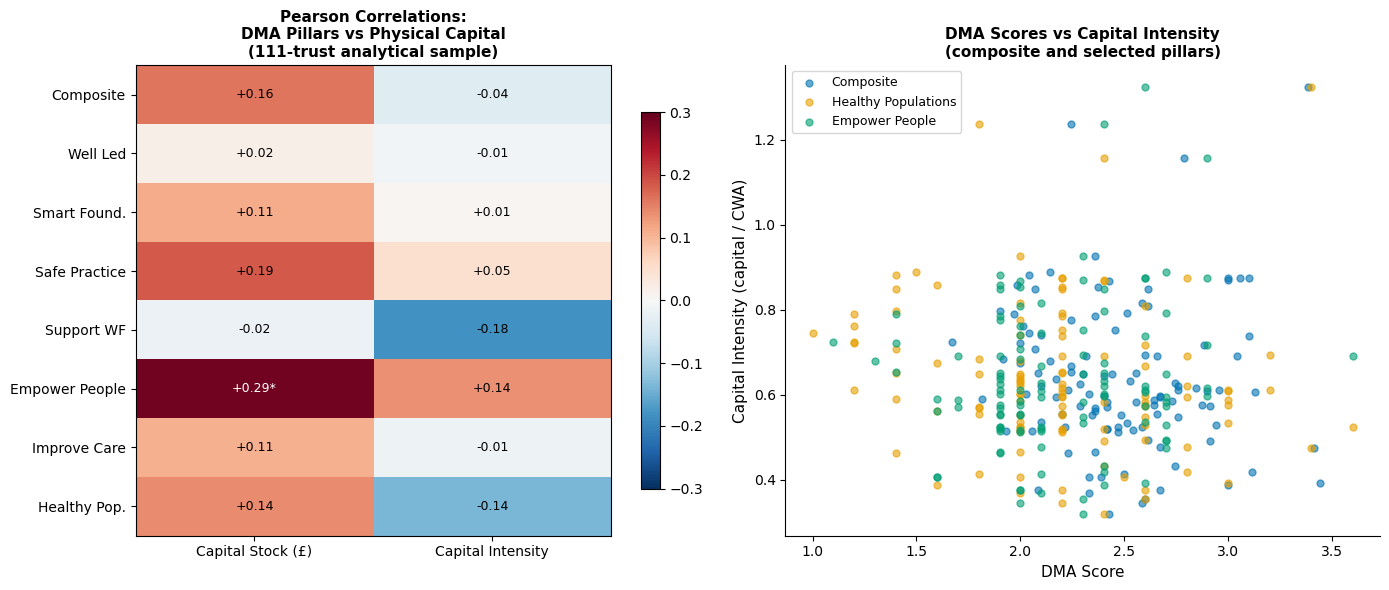


Saved capital_vs_dma_pillars.png


In [15]:
# CAPITAL CONFOUNDING CHECK analytical sample only (111 trusts)
# Tests orthogonality of physical capital to digital maturity

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Load analytical sample -- already filtered to 111 trusts
df = pd.read_csv('model_results_tac.csv')

pillar_cols = ['Well_Led', 'Ensure_Smart_Foundations', 'Safe_Practice',
               'Support_Workforce', 'Empower_People', 'Improve_Care',
               'Healthy_Populations']

key_vars = ['capital_physical', 'digital_maturity_composite',
            'cost_weighted_activity'] + pillar_cols
df = df.dropna(subset=key_vars).copy().reset_index(drop=True)

print(f"Sample: {len(df)} trusts (analytical sample)\n")

df['capital_per_cwa'] = df['capital_physical'] / df['cost_weighted_activity']

all_vars = ['digital_maturity_composite'] + pillar_cols

print(f"{'Variable':<35} {'r (capital)':<14} {'p':<10} "
      f"{'r (intensity)':<14} {'p'}")
print("-" * 80)

results = []
for var in all_vars:
    r1, p1 = stats.pearsonr(df[var], df['capital_physical'])
    r2, p2 = stats.pearsonr(df[var], df['capital_per_cwa'])
    results.append({
        'variable':    var,
        'r_capital':   r1, 'p_capital':   p1,
        'r_intensity': r2, 'p_intensity': p2
    })
    sig1 = '*' if p1 < 0.05 else ''
    sig2 = '*' if p2 < 0.05 else ''
    print(f"{var:<35} {r1:+.3f}{sig1:<9} {p1:.3f}     "
          f"{r2:+.3f}{sig2:<9} {p2:.3f}")

print("\n* p < 0.05")
print("\nNote: Bonferroni-corrected threshold for 8 tests: p < 0.006")
n_sig_bonferroni = sum(
    1 for r in results
    if r['p_capital'] < 0.006 or r['p_intensity'] < 0.006
)
print(f"Significant after Bonferroni correction: {n_sig_bonferroni} of "
      f"{len(results)*2} tests")

# FIGURE

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

capital_vars   = ['capital_physical', 'capital_per_cwa']
labels_dm      = ['Composite', 'Well Led', 'Smart Found.',
                   'Safe Practice', 'Support WF',
                   'Empower People', 'Improve Care', 'Healthy Pop.']
labels_capital = ['Capital Stock (\u00a3)', 'Capital Intensity']

corr_matrix = np.zeros((len(all_vars), len(capital_vars)))
pval_matrix = np.zeros((len(all_vars), len(capital_vars)))

for i, dv in enumerate(all_vars):
    for j, cv in enumerate(capital_vars):
        r, p = stats.pearsonr(df[dv], df[cv])
        corr_matrix[i, j] = r
        pval_matrix[i, j] = p

im = axes[0].imshow(corr_matrix, cmap='RdBu_r', vmin=-0.3, vmax=0.3,
                     aspect='auto')
axes[0].set_xticks(range(len(capital_vars)))
axes[0].set_xticklabels(labels_capital, fontsize=10)
axes[0].set_yticks(range(len(all_vars)))
axes[0].set_yticklabels(labels_dm, fontsize=10)
axes[0].set_title('Pearson Correlations:\nDMA Pillars vs Physical Capital\n'
                   '(111-trust analytical sample)',
                   fontsize=11, fontweight='bold')
for i in range(len(all_vars)):
    for j in range(len(capital_vars)):
        sig = '*' if pval_matrix[i, j] < 0.05 else ''
        axes[0].text(j, i, f"{corr_matrix[i,j]:+.2f}{sig}",
                     ha='center', va='center', fontsize=9,
                     color='white' if abs(corr_matrix[i,j]) > 0.2
                     else 'black')
plt.colorbar(im, ax=axes[0], shrink=0.8)

# Scatter -- composite and two extreme pillars vs capital intensity
for var, label, color in [
    ('digital_maturity_composite', 'Composite',          '#0072B2'),   # Okabe-Ito
    ('Healthy_Populations',        'Healthy Populations', '#E69F00'),
    ('Empower_People',             'Empower People',      '#009E73'),
]:
    axes[1].scatter(df[var], df['capital_per_cwa'],
                    alpha=0.6, s=25, color=color, label=label)

axes[1].set_xlabel('DMA Score', fontsize=11)
axes[1].set_ylabel('Capital Intensity (capital / CWA)', fontsize=11)
axes[1].set_title('DMA Scores vs Capital Intensity\n'
                   '(composite and selected pillars)',
                   fontsize=11, fontweight='bold')
axes[1].legend(fontsize=9)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('capital_vs_dma_pillars.png', dpi=300, bbox_inches='tight')
plt.show()
print("\nSaved capital_vs_dma_pillars.png")

In [16]:
import pandas as pd
import numpy as np

df = pd.read_csv('model_results_tac.csv')

def get_subtype(row):
    if row['Trust_subtype_Acute - Teaching']:
        return 'Acute - Teaching'
    elif row['Trust_subtype_Acute - Medium']:
        return 'Acute - Medium'
    elif row['Trust_subtype_Acute - Small']:
        return 'Acute - Small'
    else:
        return 'Acute - Large'

df['Trust_subtype'] = df.apply(get_subtype, axis=1)

efficiency_table = (df[['Trust_name', 'Trust_subtype', 'Region',
                          'digital_maturity_composite',
                          'efficiency_a_mean', 'efficiency_a_sd']]
                    .sort_values('efficiency_a_mean', ascending=False)
                    .copy())

efficiency_table['efficiency_pct']   = (efficiency_table['efficiency_a_mean'] * 100).round(1)
efficiency_table['inefficiency_pct'] = ((1 - efficiency_table['efficiency_a_mean']) * 100).round(1)
efficiency_table['dm_score']         = efficiency_table['digital_maturity_composite'].round(3)
efficiency_table['rank']             = range(1, len(efficiency_table) + 1)

print(f"{'Rank':<5} {'Trust':<65} {'Subtype':<22} {'Region':<12} {'DM Score':<10} {'Eff %':<8} {'Ineff %'}")
print("-" * 130)
for _, row in efficiency_table.iterrows():
    print(f"{row['rank']:<5} {row['Trust_name']:<65} {row['Trust_subtype']:<22} "
          f"{row['Region']:<12} {row['dm_score']:<10} "
          f"{row['efficiency_pct']:<8} {row['inefficiency_pct']}")

efficiency_table[['rank', 'Trust_name', 'Trust_subtype', 'Region',
                   'dm_score', 'efficiency_pct', 'inefficiency_pct']].to_csv(
    'efficiency_rankings_tac.csv', index=False)
print("\nSaved efficiency_rankings_tac.csv")

Rank  Trust                                                             Subtype                Region       DM Score   Eff %    Ineff %
----------------------------------------------------------------------------------------------------------------------------------
1     North Tees and Hartlepool NHS Foundation Trust                    Acute - Medium         North East   3.0        98.8     1.2
2     South Tyneside and Sunderland NHS Foundation Trust                Acute - Large          North East   3.443      98.6     1.4
3     Manchester University NHS Foundation Trust                        Acute - Teaching       North West   3.414      98.6     1.4
4     Royal Free London NHS Foundation Trust                            Acute - Teaching       London       2.243      98.5     1.5
5     Barts Health NHS Trust                                            Acute - Teaching       London       3.0        98.4     1.6
6     The Dudley Group NHS Foundation Trust                             A

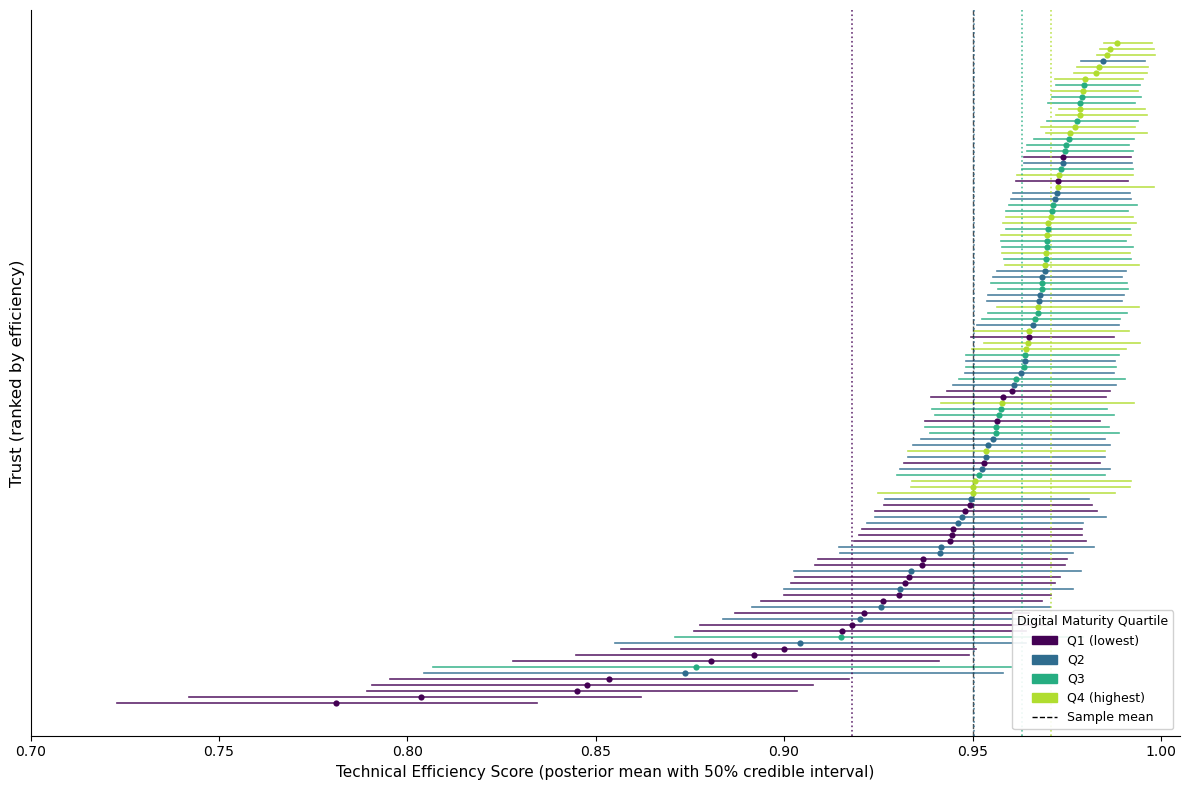

Saved caterpillar_dm_quartile_tac.png


In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import arviz as az

df = pd.read_csv('model_results_tac.csv')

def get_subtype(row):
    if row['Trust_subtype_Acute - Teaching']:
        return 'Acute - Teaching'
    elif row['Trust_subtype_Acute - Medium']:
        return 'Acute - Medium'
    elif row['Trust_subtype_Acute - Small']:
        return 'Acute - Small'
    else:
        return 'Acute - Large'

df['Trust_subtype'] = df.apply(get_subtype, axis=1)

df['dm_quartile'] = pd.qcut(df['digital_maturity_composite'], 4,
                             labels=['Q1 (lowest)', 'Q2', 'Q3', 'Q4 (highest)'])

trace_a = az.from_netcdf('trace_model_a_tac.nc')
u_posterior   = trace_a.posterior['u'].values
eff_posterior = np.exp(-u_posterior)

df['eff_mean'] = eff_posterior.mean(axis=(0, 1))
df['eff_lo25'] = np.percentile(eff_posterior, 25, axis=(0, 1))
df['eff_hi75'] = np.percentile(eff_posterior, 75, axis=(0, 1))

df_sorted = df.sort_values('eff_mean').reset_index(drop=True)
df_sorted['plot_rank'] = range(len(df_sorted))

# Colour by DM quartile (viridis: colour-blind safe, ordered, legible in greyscale)
_cols = plt.cm.viridis([0.0, 0.35, 0.62, 0.88])
quartile_shades = {
    'Q1 (lowest)':  _cols[0],
    'Q2':           _cols[1],
    'Q3':           _cols[2],
    'Q4 (highest)': _cols[3],
}

fig, ax = plt.subplots(figsize=(12, 8))

for _, row in df_sorted.iterrows():
    shade = quartile_shades[row['dm_quartile']]
    ax.plot([row['eff_lo25'], row['eff_hi75']],
            [row['plot_rank'], row['plot_rank']],
            color=shade, linewidth=1.2, alpha=0.85, zorder=2)
    ax.scatter(row['eff_mean'], row['plot_rank'],
               color=shade, s=20, zorder=3,
               edgecolors=shade, linewidths=0)

# Sample mean line
ax.axvline(x=df_sorted['eff_mean'].mean(),
           color='black', linestyle='--',
           linewidth=1, alpha=0.7)

# Quartile mean lines
for q, shade in quartile_shades.items():
    qmean = df_sorted[df_sorted['dm_quartile'] == q]['eff_mean'].mean()
    ax.axvline(x=qmean, color=shade, linestyle=':',
               linewidth=1.2, alpha=0.8)

# Legend
patches = [mpatches.Patch(color=c, label=q)
           for q, c in quartile_shades.items()]
patches.append(plt.Line2D([0], [0], color='black', linestyle='--',
                           linewidth=1, label='Sample mean'))
ax.legend(handles=patches, title='Digital Maturity Quartile',
          fontsize=9, title_fontsize=9,
          loc='lower right', framealpha=0.9)

ax.set_xlabel('Technical Efficiency Score (posterior mean with 50% credible interval)',
              fontsize=11)
ax.set_ylabel('Trust (ranked by efficiency)', fontsize=12)
ax.set_yticks([])
ax.set_xlim(np.floor((df_sorted['eff_lo25'].min() - 0.01) * 50) / 50, 1.005)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('caterpillar_dm_quartile_tac.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved caterpillar_dm_quartile_tac.png")

## Sensitivity and validation analyses

| Cell | Analysis |
|---|---|
| S0 | Setup: analytical data, model builder and helpers |
| S1 | Efficiency estimated without digital maturity in the inefficiency equation (Models A0 and A0c) |
| S1b | Caterpillar plot, Model A against Model A0 |
| S2 | Prior-width sweep for the digital maturity coefficient |
| S3 | Posterior predictive checks |
| S4 | Posterior contrast in mean efficiency, highest against lowest DMA quartile |
| S5 | Aggregate technical inefficiency |
| S6 | Cost-share priors from the 2023/24 accounts |
| S7 | Export of the analytical dataset, data dictionary and environment |
| S8 | Financial-position specifications |
| S9 | Summary of results (saved to results_summary.json) |

All reported numbers are collected in `RES` and printed by S9.

In [18]:
# S0 -- SETUP: analytical data, model builder, helpers

import os, json
import numpy as np
import pandas as pd
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

SEED = 42
assert 'sample_sfa' in globals(), 'Run cell 1 (SFA helpers) first'
import pytensor.tensor as pt
RES  = {}          # every reported number is collected here

key_vars = ['ln_cost_weighted_activity',
            'ln_fte_clinical', 'ln_fte_support',
            'ln_nle_pure_tac', 'ln_capital_physical',
            'digital_maturity_composite', 'imd_std',
            'Trust_subtype_Acute - Teaching', 'financial_deficit',
            'deficit_pct_income']

rv = (pd.read_csv('model_data_tac.csv')
        .dropna(subset=key_vars).copy().reset_index(drop=True))

# Row order must match model_results_tac.csv so trust-level arrays line up
res = pd.read_csv('model_results_tac.csv')
assert len(res) == len(rv) and (res['ods_code'].values == rv['ods_code'].values).all(), \
    "Row order differs from model_results_tac.csv -- rerun the primary model cells first"

N        = len(rv)
y        = rv['ln_cost_weighted_activity'].values
cwa      = rv['cost_weighted_activity'].values
input_cols = ['ln_fte_clinical', 'ln_fte_support', 'ln_nle_pure_tac', 'ln_capital_physical']
X        = np.column_stack([rv[c].values - rv[c].values.mean() for c in input_cols])

def standardise(x):
    return (x - x.mean()) / x.std()

dm_raw   = rv['digital_maturity_composite'].values
dm       = standardise(dm_raw)
teach    = rv['Trust_subtype_Acute - Teaching'].astype(float).values
deficit_    = deficit_z(rv['deficit_pct_income'].values)            # primary: retained deficit % income
deficit_bin = rv['financial_deficit'].astype(float).values              # binary deficit flag
deficit_op  = deficit_z(rv['deficit_operating_pct_income'].values)    # operating deficit % income
imd_     = rv['imd_std'].values

QLAB     = ['Q1', 'Q2', 'Q3', 'Q4']
quartile = np.asarray(pd.qcut(dm_raw, 4, labels=QLAB).astype(str))
below_median = dm_raw <= np.median(dm_raw)

BETA_NAMES   = ['b_clinical', 'b_support', 'b_nonlab', 'b_capital']
BETA_MU_BASE = (0.378, 0.197, 0.376, 0.049)
BETA_SD_BASE = (0.15, 0.15, 0.15, 0.10)


def build_sfa(gamma_mu=0.0, gamma_sd=0.5, include_dm=True, include_controls=True,
              beta_mu=BETA_MU_BASE, beta_sd=BETA_SD_BASE, deficit=None, include_deficit=True):
    """Four-input centred Cobb-Douglas SFA, identical in structure to Model A."""
    with pm.Model() as m:
        alpha = pm.Normal('alpha', mu=y.mean(), sigma=2)
        b = [pm.Normal(nm, mu=mu_, sigma=sd_)
             for nm, mu_, sd_ in zip(BETA_NAMES, beta_mu, beta_sd)]

        log_sigma_v  = pm.Normal('log_sigma_v', mu=-2.5, sigma=1)
        sigma_v      = pm.Deterministic('sigma_v', pm.math.exp(log_sigma_v))
        log_sigma_u  = pm.Normal('log_sigma_u', mu=-3, sigma=1)
        sigma_u_base = pm.Deterministic('sigma_u_base', pm.math.exp(log_sigma_u))

        log_su = pm.math.log(sigma_u_base) + np.zeros(N)
        if include_dm:
            g = pm.Normal('gamma_composite', mu=gamma_mu, sigma=gamma_sd)
            log_su = log_su + g * dm
        if include_controls:
            gT = pm.Normal('gamma_teaching', mu=0, sigma=0.5)
            gI = pm.Normal('gamma_imd',      mu=0, sigma=0.5)
            log_su = log_su + gT * teach + gI * imd_
            if include_deficit:
                gD = pm.Normal('gamma_deficit', mu=0, sigma=0.5)
                log_su = log_su + gD * (deficit_ if deficit is None else deficit)

        # u integrated out analytically (marginal SFA likelihood); u drawn post hoc by add_u()
        sig_u_i = pm.Deterministic('sig_u_i', (pm.math.exp(log_su)) * pt.ones(N))
        pm.Deterministic('sfa_sigma_v', sigma_v)
        mu = alpha + sum(b[k] * X[:, k] for k in range(4))
        pm.Deterministic('eps', y - mu)
        pm.CustomDist('output', mu, sigma_v, sig_u_i,
                      logp=sfa_logp, random=sfa_random, observed=y)
    return m


def fit(model, draws=5000, tune=8000, target_accept=0.97, loglik=True, progressbar=True):
    with model:
        return sample_sfa(draws, tune=tune, chains=4, target_accept=target_accept,
                         random_seed=SEED, return_inferencedata=True,
                         idata_kwargs={"log_likelihood": loglik},
                         progressbar=progressbar)


def draws_of(trace, var):
    a = trace.posterior[var].values
    return a.reshape(-1, *a.shape[2:])


def eff_draws(trace):
    """Posterior draws of TE_i = exp(-u_i), shape (S, N)."""
    return np.exp(-draws_of(trace, 'u'))


def summ(x, p=(2.5, 97.5)):
    x = np.asarray(x)
    return {'mean': float(x.mean()), 'lo': float(np.percentile(x, p[0])),
            'hi': float(np.percentile(x, p[1]))}


def fmt(s, k=3, scale=1.0, unit=''):
    return (f"{s['mean']*scale:.{k}f}{unit} "
            f"[{s['lo']*scale:.{k}f}, {s['hi']*scale:.{k}f}]")


def diag(trace):
    """Max R-hat and min bulk ESS over scalar parameters (u excluded)."""
    try:
        r, e = az.rhat(trace), az.ess(trace)
        vs = [v for v in r.data_vars if v not in ('u', 'eps', 'sig_u_i', 'sfa_sigma_v')]
        return (max(float(np.nanmax(r[v].values)) for v in vs),
                min(float(np.nanmin(e[v].values)) for v in vs))
    except Exception as ex:
        print(f"  (diagnostics unavailable: {ex})")
        return (np.nan, np.nan)


def gamma_stats(trace):
    g = draws_of(trace, 'gamma_composite')
    d = summ(g)
    d['p_neg'] = float((g < 0).mean())
    return d


def corr_draws(E, x=dm_raw):
    """Per-draw Pearson correlation between TE_i and x, shape (S,)."""
    xs = (x - x.mean()) / x.std()
    Es = (E - E.mean(1, keepdims=True)) / E.std(1, keepdims=True)
    return (Es * xs).mean(1)


# Traces from the primary run, loaded from disk if this kernel did not produce them
if 'trace_a' not in globals():
    trace_a = az.from_netcdf('trace_model_a_tac.nc')
E_a = eff_draws(trace_a)
assert E_a.shape[1] == N

RES['n_trusts'] = N
RES['model_A_gamma'] = gamma_stats(trace_a)
RES['model_A_diag']  = dict(zip(['max_rhat', 'min_ess'], diag(trace_a)))

print(f"Analytical sample: {N} trusts; quartile sizes:",
      dict(zip(*np.unique(quartile, return_counts=True))))
print(f"Model A gamma_composite: {fmt(RES['model_A_gamma'])}, "
      f"P(gamma<0) = {RES['model_A_gamma']['p_neg']:.3f}")

Analytical sample: 111 trusts; quartile sizes: {np.str_('Q1'): np.int64(29), np.str_('Q2'): np.int64(27), np.str_('Q3'): np.int64(28), np.str_('Q4'): np.int64(27)}
Model A gamma_composite: -0.453 [-1.059, 0.009], P(gamma<0) = 0.972


MODEL A0: no covariates in the inefficiency equation


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, b_clinical, b_support, b_nonlab, b_capital, log_sigma_v, log_sigma_u]


Output()

Sampling 4 chains for 8_000 tune and 5_000 draw iterations (32_000 + 20_000 draws total) took 81 seconds.



MODEL A0c: controls in sigma_u, digital maturity omitted


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, b_clinical, b_support, b_nonlab, b_capital, log_sigma_v, log_sigma_u, gamma_teaching, gamma_imd, gamma_deficit]


Output()

Sampling 4 chains for 8_000 tune and 5_000 draw iterations (32_000 + 20_000 draws total) took 82 seconds.



Correlation of technical efficiency with DMA composite
Model     Pearson (post. mean TE)   Spearman     per-draw Pearson r [95% CrI]   P(r>0)
A                0.572 (p=5.4e-11)      0.643             0.415 [0.131, 0.604]    0.995
A0               0.204 (p=3.2e-02)      0.222            0.127 [-0.081, 0.273]    0.906
A0c              0.242 (p=1.0e-02)      0.219             0.173 [0.012, 0.313]    0.981

Mean posterior TE by DMA quartile
         A      A0     A0c
Q1  0.9181  0.8974  0.9021
Q2  0.9504  0.9193  0.9239
Q3  0.9631  0.9264  0.9345
Q4  0.9709  0.9211  0.9299

Rank correlation of TE between models (Spearman):
  A vs A0 : 0.762
  A vs A0c: 0.836

PSIS-LOO comparison:
                     rank  elpd    p  elpd_diff  weight   se  dse  warning
A (DM + controls)       0  80.0  9.8        0.0    0.59  8.5  0.0    False
A0c (controls only)     1  80.0  8.9       -0.0    0.41  7.8  2.4    False
A0 (no covariates)      2  80.0  6.5       -2.0    0.00  8.0  2.9    False


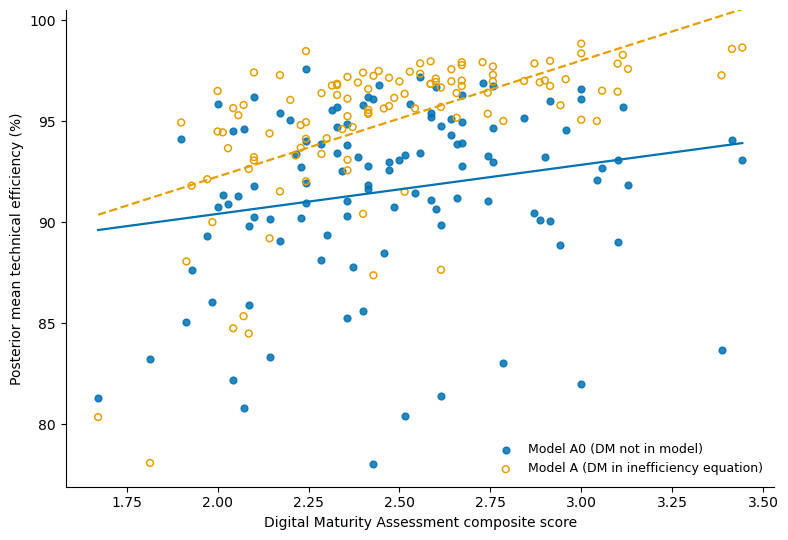

In [19]:
# S1 -- MODELS A0 AND A0c: DIGITAL MATURITY OMITTED FROM sigma_u

print("=" * 60)
print("MODEL A0: no covariates in the inefficiency equation")
print("=" * 60)
model_a0 = build_sfa(include_dm=False, include_controls=False)
trace_a0 = fit(model_a0)
trace_a0.to_netcdf('trace_model_a0_tac.nc')

print("\n" + "=" * 60)
print("MODEL A0c: controls in sigma_u, digital maturity omitted")
print("=" * 60)
model_a0c = build_sfa(include_dm=False, include_controls=True)
trace_a0c = fit(model_a0c)
trace_a0c.to_netcdf('trace_model_a0c_tac.nc')

E_a0, E_a0c = eff_draws(trace_a0), eff_draws(trace_a0c)

for lab, E, tr in [('A', E_a, trace_a), ('A0', E_a0, trace_a0), ('A0c', E_a0c, trace_a0c)]:
    te = E.mean(0)
    r_d = corr_draws(E)
    pear = stats.pearsonr(te, dm_raw)
    spear = stats.spearmanr(te, dm_raw)
    RES[f'corr_TE_DM_{lab}'] = {
        'pearson_postmean': float(pear[0]), 'pearson_p': float(pear[1]),
        'spearman_postmean': float(spear[0]), 'spearman_p': float(spear[1]),
        'pearson_per_draw': summ(r_d),
        'P_r_gt_0': float((r_d > 0).mean())}
    RES[f'quartile_means_{lab}'] = {q: float(te[quartile == q].mean()) for q in QLAB}
    RES[f'diag_{lab}'] = dict(zip(['max_rhat', 'min_ess'], diag(tr)))

print("\nCorrelation of technical efficiency with DMA composite")
print(f"{'Model':6s} {'Pearson (post. mean TE)':>26s} {'Spearman':>10s} "
      f"{'per-draw Pearson r [95% CrI]':>32s} {'P(r>0)':>8s}")
for lab in ['A', 'A0', 'A0c']:
    c = RES[f'corr_TE_DM_{lab}']
    print(f"{lab:6s} {c['pearson_postmean']:>15.3f} (p={c['pearson_p']:.1e}) "
          f"{c['spearman_postmean']:>10.3f} {fmt(c['pearson_per_draw']):>32s} "
          f"{c['P_r_gt_0']:>8.3f}")

print("\nMean posterior TE by DMA quartile")
print(pd.DataFrame({lab: RES[f'quartile_means_{lab}'] for lab in ['A', 'A0', 'A0c']}).round(4))

print("\nRank correlation of TE between models (Spearman):")
print(f"  A vs A0 : {stats.spearmanr(E_a.mean(0),  E_a0.mean(0))[0]:.3f}")
print(f"  A vs A0c: {stats.spearmanr(E_a.mean(0),  E_a0c.mean(0))[0]:.3f}")

# Does adding DM to sigma_u improve out-of-sample predictive fit?
# (the log-likelihood is the per-trust marginal over u, so PSIS-LOO is valid)
try:
    cmp_a0 = az.compare({'A (DM + controls)': trace_a,
                         'A0c (controls only)': trace_a0c,
                         'A0 (no covariates)': trace_a0})
    print("\nPSIS-LOO comparison:")
    print(cmp_a0)
    RES['loo_compare_A_A0'] = cmp_a0.reset_index().to_dict(orient='records')
except Exception as ex:
    print(f"LOO comparison failed: {ex}")

# Figure: TE (A0) against DMA, with Model A for reference
fig, ax = plt.subplots(figsize=(8, 5.5))
# Okabe-Ito colours (colour-blind safe)
C_A0, C_A = '#0072B2', '#E69F00'
ax.scatter(dm_raw, E_a0.mean(0) * 100, s=24, color=C_A0, alpha=0.85,
           label='Model A0 (DM not in model)')
ax.scatter(dm_raw, E_a.mean(0) * 100, s=24, facecolors='none', edgecolors=C_A, linewidths=1.1,
           label='Model A (DM in inefficiency equation)')
for E, ls, col in [(E_a0, '-', C_A0), (E_a, '--', C_A)]:
    sl, ic = np.polyfit(dm_raw, E.mean(0) * 100, 1)
    xx = np.linspace(dm_raw.min(), dm_raw.max(), 50)
    ax.plot(xx, ic + sl * xx, ls, color=col, lw=1.6)
ax.set_ylim(top=100.5)           # efficiency cannot exceed 100%; fitted lines are clipped
ax.set_xlabel('Digital Maturity Assessment composite score')
ax.set_ylabel('Posterior mean technical efficiency (%)')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.savefig('te_vs_dma_A0.png', dpi=300, bbox_inches='tight')
plt.show()

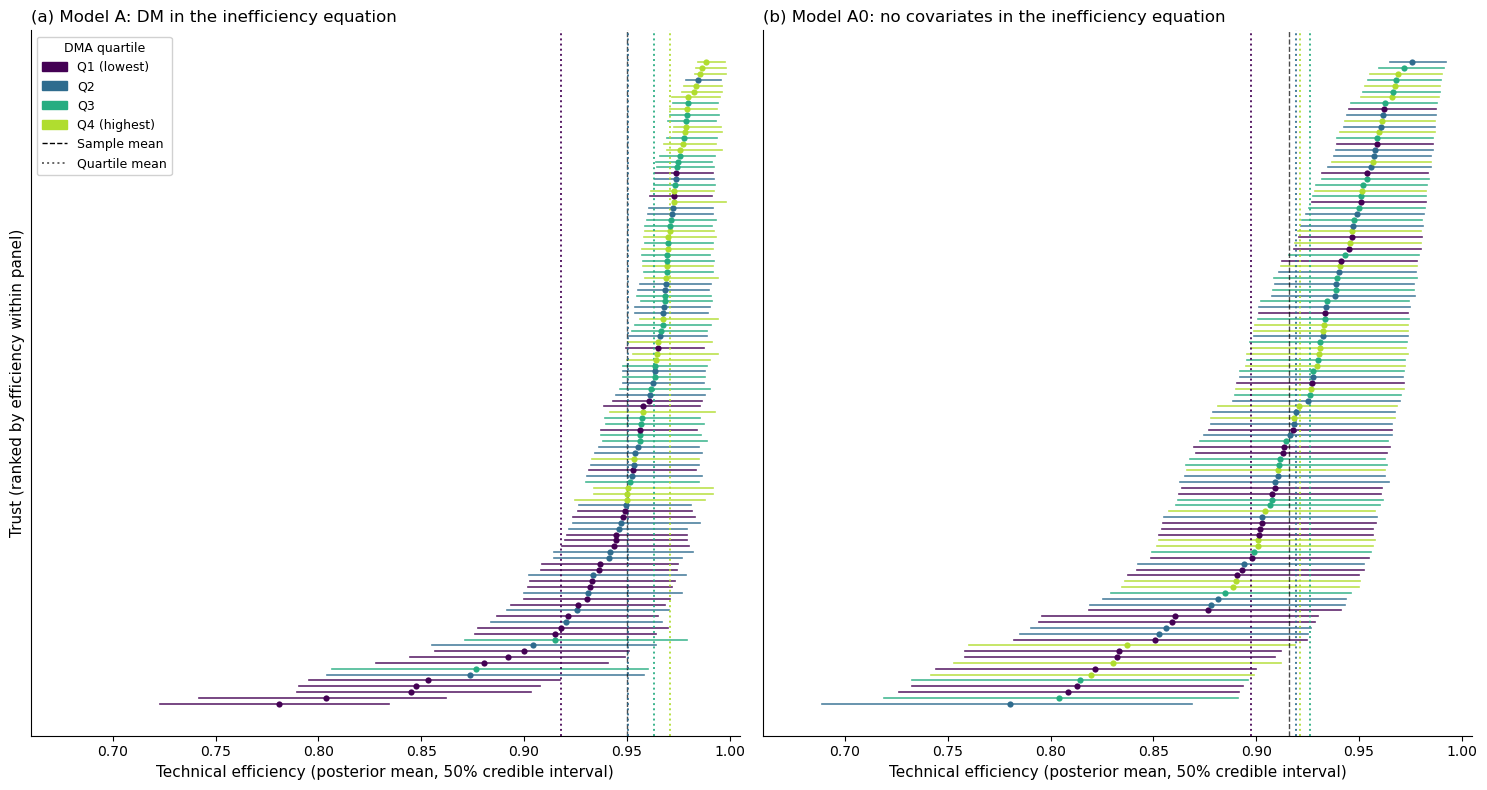

Saved caterpillar_A_vs_A0.png


In [20]:
# S1b -- CATERPILLAR PLOT, MODEL A vs MODEL A0 (two panels)

import matplotlib.patches as mpatches

cat_df = pd.read_csv('model_results_tac.csv')
cat_df['dm_quartile'] = pd.qcut(cat_df['digital_maturity_composite'], 4,
                                labels=['Q1 (lowest)', 'Q2', 'Q3', 'Q4 (highest)'])
_cols = plt.cm.viridis([0.0, 0.35, 0.62, 0.88])
q_cols = dict(zip(['Q1 (lowest)', 'Q2', 'Q3', 'Q4 (highest)'], _cols))

panels = [('(a) Model A: DM in the inefficiency equation', eff_draws(trace_a)),
          ('(b) Model A0: no covariates in the inefficiency equation', eff_draws(trace_a0))]
lo_all = min(np.percentile(E, 25, axis=0).min() for _, E in panels)
xlim = (np.floor((lo_all - 0.01) * 50) / 50, 1.005)

fig, axes = plt.subplots(1, 2, figsize=(15, 8), sharex=True)
for ax, (title, E) in zip(axes, panels):
    d = cat_df[['dm_quartile']].copy()
    d['m'] = E.mean(0)
    d['lo'] = np.percentile(E, 25, axis=0)
    d['hi'] = np.percentile(E, 75, axis=0)
    d = d.sort_values('m').reset_index(drop=True)
    for k, r in d.iterrows():
        col = q_cols[r['dm_quartile']]
        ax.plot([r['lo'], r['hi']], [k, k], color=col, lw=1.2, alpha=0.85, zorder=2)
        ax.scatter(r['m'], k, color=col, s=20, zorder=3, linewidths=0)
    ax.axvline(d['m'].mean(), color='black', ls='--', lw=1, alpha=0.7)
    for q, col in q_cols.items():
        ax.axvline(d.loc[d['dm_quartile'] == q, 'm'].mean(), color=col, ls=':', lw=1.4, alpha=0.9)
    ax.set_title(title, fontsize=12, loc='left')
    ax.set_yticks([]); ax.set_xlim(*xlim)
    ax.set_xlabel('Technical efficiency (posterior mean, 50% credible interval)', fontsize=11)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('Trust (ranked by efficiency within panel)', fontsize=11)

handles = [mpatches.Patch(color=c, label=q) for q, c in q_cols.items()]
handles += [plt.Line2D([0], [0], color='black', ls='--', lw=1, label='Sample mean'),
            plt.Line2D([0], [0], color='0.4', ls=':', lw=1.4, label='Quartile mean')]
axes[0].legend(handles=handles, title='DMA quartile', fontsize=9, title_fontsize=9,
               loc='upper left', framealpha=0.9)
plt.tight_layout()
plt.savefig('caterpillar_A_vs_A0.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved caterpillar_A_vs_A0.png")

Fitting gamma ~ N(0, 0.1^2) ...


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, b_clinical, b_support, b_nonlab, b_capital, log_sigma_v, log_sigma_u, gamma_composite, gamma_teaching, gamma_imd, gamma_deficit]


Output()

Sampling 4 chains for 8_000 tune and 5_000 draw iterations (32_000 + 20_000 draws total) took 82 seconds.


   gamma -0.074 [-0.241, 0.087]  P<0 0.815  max rhat 1.001  min ess 3880
Fitting gamma ~ N(0, 0.15^2) ...


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, b_clinical, b_support, b_nonlab, b_capital, log_sigma_v, log_sigma_u, gamma_composite, gamma_teaching, gamma_imd, gamma_deficit]


... (27 outputs left out)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, b_clinical, b_support, b_nonlab, b_capital, log_sigma_v, log_sigma_u, gamma_composite, gamma_teaching, gamma_imd, gamma_deficit]


Output()

Sampling 4 chains for 8_000 tune and 5_000 draw iterations (32_000 + 20_000 draws total) took 81 seconds.


   gamma -0.132 [-0.426, 0.125]  P<0 0.846  max rhat 1.002  min ess 4036
                            prior  prior_mu  prior_sd  post_mean  ci_lo  ci_hi  P_gamma_lt_0  max_rhat  min_ess  excludes_zero
                      N(0, 0.1^2)       0.0      0.10     -0.074 -0.241  0.087         0.815     1.001 3880.221          False
                     N(0, 0.15^2)       0.0      0.15     -0.129 -0.374  0.087         0.875     1.001 4736.420          False
                      N(0, 0.2^2)       0.0      0.20     -0.186 -0.496  0.076         0.913     1.001 4723.191          False
                      N(0, 0.3^2)       0.0      0.30     -0.286 -0.713  0.053         0.946     1.001 4010.423          False
                      N(0, 0.5^2)       0.0      0.50     -0.453 -1.059  0.009         0.972     1.001 4971.823          False
                     N(0, 0.75^2)       0.0      0.75     -0.582 -1.339 -0.014         0.979     1.001 4482.562           True
                        N(0, 1^2)     

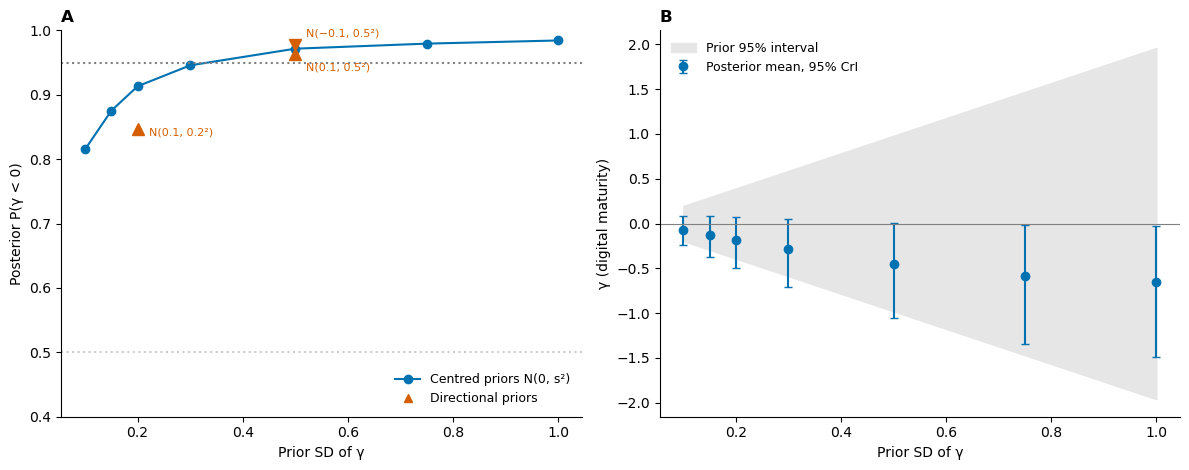

In [21]:
# S2 -- PRIOR-WIDTH SWEEP FOR gamma_composite

sweep_specs = ([(f"N(0, {sd:g}^2)", 0.0, sd) for sd in [0.10, 0.15, 0.20, 0.30, 0.50, 0.75, 1.00]] +
               [("N(-0.1, 0.5^2) favourable", -0.1, 0.5),
                ("N(+0.1, 0.5^2) adverse",     +0.1, 0.5),
                ("N(+0.1, 0.2^2) adverse, sceptical", +0.1, 0.2)])

import os
rows = []
for label, mu0, sd0 in sweep_specs:
    fn = f"trace_sweep_mu{mu0:+.2f}_sd{sd0:.2f}.nc"
    if (mu0, sd0) == (0.0, 0.50):
        print(f"gamma ~ {label}: identical to Model A, reusing trace_a", flush=True)
        tr = trace_a
    elif os.path.exists(fn):
        print(f"Loading gamma ~ {label} from {fn}", flush=True)
        tr = az.from_netcdf(fn)
    else:
        print(f"Fitting gamma ~ {label} ...", flush=True)
        tr = fit(build_sfa(gamma_mu=mu0, gamma_sd=sd0), loglik=False, progressbar=True)
        tr.to_netcdf(fn)
    g = gamma_stats(tr)
    rh, es = diag(tr)
    print(f"   gamma {g['mean']:.3f} [{g['lo']:.3f}, {g['hi']:.3f}]  P<0 {g['p_neg']:.3f}  "
          f"max rhat {rh:.3f}  min ess {es:.0f}", flush=True)
    rows.append({'prior': label, 'prior_mu': mu0, 'prior_sd': sd0,
                 'post_mean': g['mean'], 'ci_lo': g['lo'], 'ci_hi': g['hi'],
                 'P_gamma_lt_0': g['p_neg'], 'max_rhat': rh, 'min_ess': es,
                 'excludes_zero': g['hi'] < 0})
    if (mu0, sd0) == (0.0, 0.20):
        trace_scep = tr
        tr.to_netcdf('trace_model_a_sceptical.nc')

sweep = pd.DataFrame(rows)
sweep.to_csv('prior_sweep.csv', index=False)
RES['prior_sweep'] = sweep.to_dict(orient='records')
pd.set_option('display.width', 160)
print(sweep.round(3).to_string(index=False))

# Smallest centred prior SD at which P(gamma<0) >= 0.95
cen = sweep[sweep['prior_mu'] == 0].sort_values('prior_sd')
ok = cen[cen['P_gamma_lt_0'] >= 0.95]
RES['min_prior_sd_for_P95'] = float(ok['prior_sd'].min()) if len(ok) else None
print(f"\nSmallest centred prior SD giving P(gamma<0) >= 0.95: {RES['min_prior_sd_for_P95']}")

# Figure
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
C_CEN, C_DIR = '#0072B2', '#D55E00'     # Okabe-Ito
dir_lab = {(-0.1, 0.5): ('v', 'N(\u22120.1, 0.5\u00b2)', (8, 6)),
           (0.1, 0.5):  ('^', 'N(0.1, 0.5\u00b2)', (8, -12)),
           (0.1, 0.2):  ('^', 'N(0.1, 0.2\u00b2)', (8, -4))}
ax = axes[0]
ax.plot(cen['prior_sd'], cen['P_gamma_lt_0'], 'o-', color=C_CEN, label='Centred priors N(0, s\u00b2)')
for _, r in sweep[sweep['prior_mu'] != 0].iterrows():
    mk, lab, off = dir_lab[(round(r['prior_mu'], 2), round(r['prior_sd'], 2))]
    ax.plot(r['prior_sd'], r['P_gamma_lt_0'], mk, color=C_DIR, ms=8)
    ax.annotate(lab, (r['prior_sd'], r['P_gamma_lt_0']), textcoords='offset points',
                xytext=off, fontsize=8, color=C_DIR)
ax.plot([], [], '^', color=C_DIR, label='Directional priors')
ax.axhline(0.95, ls=':', color='0.5'); ax.axhline(0.5, ls=':', color='0.8')
ax.set_xlabel('Prior SD of \u03b3'); ax.set_ylabel('Posterior P(\u03b3 < 0)')
ax.set_ylim(0.4, 1.0); ax.legend(frameon=False, fontsize=9, loc='lower right')
ax.set_title('A', loc='left', fontweight='bold')
ax.spines[['top', 'right']].set_visible(False)

ax = axes[1]
ax.fill_between(cen['prior_sd'], -1.96 * cen['prior_sd'], 1.96 * cen['prior_sd'],
                color='0.9', label='Prior 95% interval')
ax.errorbar(cen['prior_sd'], cen['post_mean'],
            yerr=[cen['post_mean'] - cen['ci_lo'], cen['ci_hi'] - cen['post_mean']],
            fmt='o', color=C_CEN, capsize=3, label='Posterior mean, 95% CrI')
ax.axhline(0, color='0.5', lw=0.8)
ax.set_xlabel('Prior SD of \u03b3'); ax.set_ylabel('\u03b3 (digital maturity)')
ax.legend(frameon=False, fontsize=9, loc='upper left')
ax.set_title('B', loc='left', fontweight='bold')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('prior_sweep.png', dpi=300, bbox_inches='tight')
plt.show()

Sampling: [output]


            statistic  observed  replicated_mean  rep_lo  rep_hi  bayes_p
          mean ln CWA   20.2038          20.2009 20.1689 20.2304   0.4342
            SD ln CWA    0.5276           0.5344  0.5002  0.5852   0.5883
           min ln CWA   18.8663          18.8537 17.5654 19.2185   0.7028
           max ln CWA   21.5405          21.5132 21.3444 21.7072   0.3715
      OLS residual SD    0.1100           0.1248  0.0909  0.2189   0.6562
OLS residual skewness   -0.4198          -0.9190 -5.2619  0.2277   0.4722

Bayesian p-values near 0 or 1 indicate misfit; values between ~0.05 and 0.95 are adequate.

Pareto k: max 0.62; 0 of 111 above 0.7


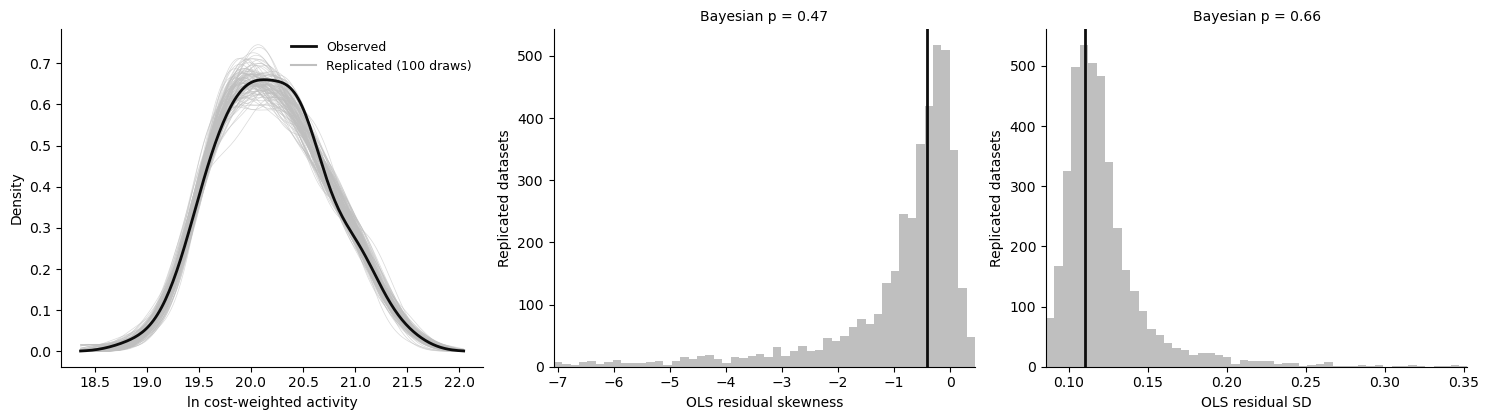

In [22]:
# S3 -- POSTERIOR PREDICTIVE CHECKS (Model A)

if 'model_a' not in globals():
    model_a = build_sfa()          # same structure and variable names as Model A

with model_a:
    ppc = pm.sample_posterior_predictive(trace_a, random_seed=SEED, progressbar=False)
yrep_all = ppc.posterior_predictive['output'].values
yrep_all = yrep_all.reshape(-1, yrep_all.shape[-1])
rng  = np.random.default_rng(SEED)
yrep = yrep_all[rng.choice(len(yrep_all), size=min(4000, len(yrep_all)), replace=False)]

X1 = np.column_stack([np.ones(N), X])
M  = np.eye(N) - X1 @ np.linalg.pinv(X1)          # residual-maker
resid_obs  = M @ y
resid_rep  = yrep @ M.T

tests = {
    'mean ln CWA':         (y.mean(),             yrep.mean(1)),
    'SD ln CWA':           (y.std(),              yrep.std(1)),
    'min ln CWA':          (y.min(),              yrep.min(1)),
    'max ln CWA':          (y.max(),              yrep.max(1)),
    'OLS residual SD':     (resid_obs.std(),      resid_rep.std(1)),
    'OLS residual skewness': (stats.skew(resid_obs), stats.skew(resid_rep, axis=1)),
}
ppc_rows = []
for name, (obs, rep) in tests.items():
    ppc_rows.append({'statistic': name, 'observed': obs,
                     'replicated_mean': rep.mean(),
                     'rep_lo': np.percentile(rep, 2.5), 'rep_hi': np.percentile(rep, 97.5),
                     'bayes_p': float((rep >= obs).mean())})
ppc_tab = pd.DataFrame(ppc_rows)
print(ppc_tab.round(4).to_string(index=False))
print("\nBayesian p-values near 0 or 1 indicate misfit; values between ~0.05 and 0.95 are adequate.")
RES['ppc'] = ppc_tab.to_dict(orient='records')
ppc_tab.to_csv('posterior_predictive_checks.csv', index=False)

# PSIS-LOO Pareto k diagnostics (k < 0.7 indicates reliable estimates)
try:
    loo_a = az.loo(trace_a, pointwise=True)
    k = np.asarray(loo_a.pareto_k).ravel()
    RES['pareto_k'] = {'max': float(k.max()), 'n_gt_0.7': int((k > 0.7).sum()), 'n': int(k.size)}
    print(f"\nPareto k: max {k.max():.2f}; {int((k > 0.7).sum())} of {k.size} above 0.7")
except Exception as ex:
    print(f"Pareto k unavailable: {ex}")

# Figure
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
ax = axes[0]
grid = np.linspace(y.min() - 0.5, y.max() + 0.5, 200)
for r in yrep[:100]:
    ax.plot(grid, stats.gaussian_kde(r)(grid), color='0.75', lw=0.5, alpha=0.6)
ax.plot(grid, stats.gaussian_kde(y)(grid), color='0.05', lw=2, label='Observed')
ax.plot([], [], color='0.75', label='Replicated (100 draws)')
ax.set_xlabel('ln cost-weighted activity'); ax.set_ylabel('Density')
ax.legend(frameon=False, fontsize=9)
for ax, name in zip(axes[1:], ['OLS residual skewness', 'OLS residual SD']):
    obs, rep = tests[name]
    lo, hi = np.percentile(rep, [0.5, 99.5])
    lo, hi = min(lo, obs), max(hi, obs)
    ax.hist(rep[(rep >= lo) & (rep <= hi)], bins=50, color='0.75')
    ax.set_xlim(lo, hi)
    ax.axvline(obs, color='0.05', lw=2)
    ax.set_xlabel(name); ax.set_ylabel('Replicated datasets')
    ax.set_title(f"Bayesian p = {(rep >= obs).mean():.2f}", fontsize=10)
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('posterior_predictive_checks.png', dpi=300, bbox_inches='tight')
plt.show()

In [23]:
# S4 -- POSTERIOR CONTRAST IN MEAN TE, Q4 MINUS Q1 (and above vs below median)


traces_for_contrast = {'A': E_a, 'A0': E_a0, 'A0c': E_a0c}
if 'trace_scep' in globals():
    traces_for_contrast['A, sceptical prior N(0,0.2^2)'] = eff_draws(trace_scep)

rows = []
for lab, E in traces_for_contrast.items():
    q4q1 = E[:, quartile == 'Q4'].mean(1) - E[:, quartile == 'Q1'].mean(1)
    med  = E[:, ~below_median].mean(1) - E[:, below_median].mean(1)
    rows.append({'model': lab,
                 'Q4-Q1 (pp)': fmt(summ(q4q1), 2, 100),
                 'P(Q4>Q1)': float((q4q1 > 0).mean()),
                 'above-below median (pp)': fmt(summ(med), 2, 100),
                 'P(above>below)': float((med > 0).mean())})
    RES[f'contrast_{lab}'] = {'q4_minus_q1': summ(q4q1), 'p_q4_gt_q1': float((q4q1 > 0).mean()),
                              'above_minus_below_median': summ(med),
                              'p_above_gt_below': float((med > 0).mean())}
print(pd.DataFrame(rows).to_string(index=False))

                        model         Q4-Q1 (pp)  P(Q4>Q1) above-below median (pp)  P(above>below)
                            A  5.28 [1.27, 8.93]   0.99380       3.33 [0.86, 5.62]         0.99510
                           A0 2.37 [-0.49, 5.75]   0.90560      1.58 [-0.37, 3.81]         0.90025
                          A0c 2.78 [-0.07, 5.87]   0.97065       1.96 [0.02, 3.99]         0.97810
A, sceptical prior N(0,0.2^2)  4.16 [0.32, 7.79]   0.98500       2.71 [0.26, 4.98]         0.98805


In [24]:
# S5 -- AGGREGATE TECHNICAL INEFFICIENCY, WITH POSTERIOR UNCERTAINTY


def aggregate(E):
    lost  = cwa[None, :] * (1.0 / E - 1.0)
    total = lost.sum(1)
    out = {'total_lost_gbp_m': summ(total / 1e6),
           'total_lost_pct_of_cwa': summ(total / cwa.sum() * 100),
           'Q1_share_of_lost_pct': summ(lost[:, quartile == 'Q1'].sum(1) / total * 100),
           'Q1_share_of_cwa_pct': float(cwa[quartile == 'Q1'].sum() / cwa.sum() * 100)}
    for q in QLAB:
        out[f'loss_rate_{q}_pct'] = summ(lost[:, quartile == q].sum(1) / cwa[quartile == q].sum() * 100)
    te_q4 = E[:, quartile == 'Q4'].mean(1, keepdims=True)
    Eq1   = E[:, quartile == 'Q1']
    gain  = (cwa[quartile == 'Q1'][None, :] * (np.maximum(te_q4 / Eq1, 1.0) - 1.0)).sum(1)
    out['illustrative_Q1_to_Q4meanTE_gbp_m'] = summ(gain / 1e6)
    out['illustrative_Q1_to_Q4meanTE_pct_of_cwa'] = summ(gain / cwa.sum() * 100)
    return out

agg_sets = {'A': E_a, 'A0': E_a0}
if 'trace_scep' in globals():
    agg_sets['A, sceptical prior'] = eff_draws(trace_scep)

for lab, E in agg_sets.items():
    a = aggregate(E)
    RES[f'aggregate_{lab}'] = a
    print(f"\n--- {lab} ---")
    print(f"  Total lost output vs frontier: GBP {fmt(a['total_lost_gbp_m'], 0)}m "
          f"= {fmt(a['total_lost_pct_of_cwa'], 2)}% of total CWA (GBP {cwa.sum()/1e9:.1f}bn)")
    print(f"  Share of lost output in Q1:    {fmt(a['Q1_share_of_lost_pct'], 1)}% "
          f"(Q1 holds {a['Q1_share_of_cwa_pct']:.1f}% of CWA)")
    print("  Loss rate by quartile (% of quartile CWA): " +
          ", ".join(f"{q} {a[f'loss_rate_{q}_pct']['mean']:.2f}" for q in QLAB))
    print(f"  ILLUSTRATIVE ONLY, Q1 trusts at Q4 mean TE: GBP "
          f"{fmt(a['illustrative_Q1_to_Q4meanTE_gbp_m'], 0)}m")


--- A ---
  Total lost output vs frontier: GBP 3827 [1065, 8920]m = 5.03 [1.40, 11.73]% of total CWA (GBP 76.1bn)
  Share of lost output in Q1:    36.3 [21.4, 57.8]% (Q1 holds 19.3% of CWA)
  Loss rate by quartile (% of quartile CWA): Q1 8.66, Q2 5.15, Q3 4.23, Q4 3.03
  ILLUSTRATIVE ONLY, Q1 trusts at Q4 mean TE: GBP 865 [262, 1499]m

--- A0 ---
  Total lost output vs frontier: GBP 7285 [722, 12184]m = 9.58 [0.95, 16.02]% of total CWA (GBP 76.1bn)
  Share of lost output in Q1:    22.8 [16.6, 27.9]% (Q1 holds 19.3% of CWA)
  Loss rate by quartile (% of quartile CWA): Q1 11.62, Q2 8.76, Q3 8.98, Q4 9.56
  ILLUSTRATIVE ONLY, Q1 trusts at Q4 mean TE: GBP 639 [36, 1227]m

--- A, sceptical prior ---
  Total lost output vs frontier: GBP 5195 [1198, 10111]m = 6.83 [1.57, 13.29]% of total CWA (GBP 76.1bn)
  Share of lost output in Q1:    28.6 [19.3, 41.4]% (Q1 holds 19.3% of CWA)
  Loss rate by quartile (% of quartile CWA): Q1 9.75, Q2 6.79, Q3 6.17, Q4 5.37
  ILLUSTRATIVE ONLY, Q1 trusts at 

In [25]:
# S6 -- COST-SHARE PRIORS FROM THE 2023/24 ACCOUNTS (priors from a year other than the estimation year)


if 'data_all' not in globals() or 'providers_all' not in globals():
    raise RuntimeError("Run cell 2 (TAC extraction) in this kernel first: data_all is needed")

def extract_year(ws, sub, main, year, name):
    r = data_all[(data_all['WorkSheetName'] == ws) & (data_all['SubCode'] == sub) &
                 (data_all['MainCode'] == main) & (data_all['tac_year'] == year)]
    r = r[['OrganisationName', 'Total']].copy()
    r[name] = pd.to_numeric(r['Total'], errors='coerce') * 1000
    r = r.merge(providers_all, left_on='OrganisationName', right_on='org_name', how='left')
    return r.dropna(subset=['ods_code']).drop_duplicates('ods_code')[['ods_code', name]]

Y = '2023-24'
t23 = (extract_year('TAC09 Staff', 'STA0360',  'A09CY01', Y, 'staff23')
       .merge(extract_year('TAC02 SoCI', 'SCI0125A', 'A02CY01', Y, 'opex23'), on='ods_code', how='outer')
       .merge(extract_year('TAC03 SoFP', 'BAL1110',  'A03CY01', Y, 'ppe23'),  on='ods_code', how='outer')
       .merge(extract_year('TAC03 SoFP', 'BAL1115',  'A03CY01', Y, 'rou23'),  on='ods_code', how='outer'))
t23['opex23'] = t23['opex23'].abs()
t23['cap23']  = t23['ppe23'].fillna(0) + t23['rou23'].fillna(0)
t23['nle23']  = (t23['opex23'] - t23['staff23']).clip(lower=0)

s = rv[['ods_code', 'fte_clinical', 'fte_support', 'fte_total']].merge(t23, on='ods_code', how='left')
s = s.dropna(subset=['staff23', 'opex23']).copy()
s = s[(s['cap23'] > 0) & (s['nle23'] > 0)]
print(f"Trusts with usable 2023/24 TAC data: {len(s)} of {N}")
if len(s) < 50:
    raise RuntimeError("Too few 2023/24 matches -- check subcodes/main codes in the 2023-24 TAC file")

cost = pd.DataFrame({
    'clin': s['staff23'] * s['fte_clinical'] / s['fte_total'],
    'adm':  s['staff23'] * s['fte_support']    / s['fte_total'],
    'nle':  s['nle23'],
    'cap':  s['cap23'] * 0.10})            # 10% capital service flow, as in the cost-share cell
shares23 = cost.div(cost.sum(1), axis=0).mean()
BETA_MU_2324 = tuple(float(v) for v in shares23.values)
RES['cost_shares_2324'] = dict(zip(BETA_NAMES, BETA_MU_2324))
RES['cost_shares_2425'] = dict(zip(BETA_NAMES, BETA_MU_BASE))
RES['n_trusts_2324_shares'] = int(len(s))
print("Prior means (cost shares):")
print(pd.DataFrame({'2024/25': BETA_MU_BASE, '2023/24': BETA_MU_2324},
                   index=BETA_NAMES).round(3))

trace_a2324 = fit(build_sfa(beta_mu=BETA_MU_2324), loglik=False)
trace_a2324.to_netcdf('trace_model_a_priors2324.nc')
E_2324 = eff_draws(trace_a2324)
g = gamma_stats(trace_a2324)
RES['model_A_priors2324'] = {
    'gamma': g,
    'betas': {b: summ(draws_of(trace_a2324, b)) for b in BETA_NAMES},
    'rts': summ(sum(draws_of(trace_a2324, b) for b in BETA_NAMES)),
    'te_spearman_vs_A': float(stats.spearmanr(E_2324.mean(0), E_a.mean(0))[0]),
    'diag': dict(zip(['max_rhat', 'min_ess'], diag(trace_a2324)))}
RES['model_A_betas'] = {b: summ(draws_of(trace_a, b)) for b in BETA_NAMES}
RES['model_A_rts']   = summ(sum(draws_of(trace_a, b) for b in BETA_NAMES))

print(f"\ngamma_composite with 2023/24 priors: {fmt(g)}, P(gamma<0) = {g['p_neg']:.3f}")
print(f"Spearman correlation of TE with Model A: {RES['model_A_priors2324']['te_spearman_vs_A']:.4f}")
print("\nElasticities: Model A vs 2023/24 priors")
for b in BETA_NAMES:
    print(f"  {b:11s} {fmt(RES['model_A_betas'][b])}   {fmt(RES['model_A_priors2324']['betas'][b])}")
print(f"  {'RTS':11s} {fmt(RES['model_A_rts'])}   {fmt(RES['model_A_priors2324']['rts'])}")

Trusts with usable 2023/24 TAC data: 99 of 111
Prior means (cost shares):
            2024/25  2023/24
b_clinical    0.378    0.374
b_support     0.197    0.195
b_nonlab      0.376    0.379
b_capital     0.049    0.052


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, b_clinical, b_support, b_nonlab, b_capital, log_sigma_v, log_sigma_u, gamma_composite, gamma_teaching, gamma_imd, gamma_deficit]


Output()

Sampling 4 chains for 8_000 tune and 5_000 draw iterations (32_000 + 20_000 draws total) took 75 seconds.



gamma_composite with 2023/24 priors: -0.461 [-1.077, 0.008], P(gamma<0) = 0.973
Spearman correlation of TE with Model A: 0.9998

Elasticities: Model A vs 2023/24 priors
  b_clinical  0.394 [0.223, 0.561]   0.394 [0.227, 0.558]
  b_support   0.211 [0.098, 0.323]   0.210 [0.098, 0.323]
  b_nonlab    0.289 [0.167, 0.414]   0.289 [0.167, 0.414]
  b_capital   0.045 [-0.036, 0.126]   0.046 [-0.036, 0.128]
  RTS         0.939 [0.890, 0.986]   0.938 [0.890, 0.987]


In [26]:
# S7 -- EXPORT OF THE ANALYTICAL DATASET


from importlib.metadata import version, PackageNotFoundError
import platform

os.makedirs('zenodo_deposit', exist_ok=True)

def subtype(r):
    for s_ in ['Teaching', 'Medium', 'Small']:
        if r.get(f'Trust_subtype_Acute - {s_}', False):
            return f'Acute - {s_}'
    return 'Acute - Large'

out = rv.copy()
out['trust_subtype'] = out.apply(subtype, axis=1)
out['teaching'] = out['Trust_subtype_Acute - Teaching'].astype(int)
out['efficiency_A_mean'] = E_a.mean(0)
out['efficiency_A_sd']   = E_a.std(0)
out['efficiency_A_lo95'] = np.percentile(E_a, 2.5, axis=0)
out['efficiency_A_hi95'] = np.percentile(E_a, 97.5, axis=0)
out['efficiency_A0_mean'] = E_a0.mean(0)
out['dma_quartile'] = quartile

pillar_cols = ['Well_Led', 'Ensure_Smart_Foundations', 'Safe_Practice',
               'Support_Workforce', 'Empower_People', 'Improve_Care', 'Healthy_Populations']

DICT = [
 ('ods_code', 'NHS ODS organisation code', 'NHS Oversight Framework'),
 ('Trust_name', 'Trust name', 'NHS Oversight Framework'),
 ('Region', 'NHS England region', 'NHS Oversight Framework'),
 ('trust_subtype', 'Acute trust subtype', 'NHS Oversight Framework'),
 ('teaching', '1 = acute teaching trust', 'NHS Oversight Framework'),
 ('financial_deficit', '1 = trust recorded in financial deficit (sensitivity analysis only)', 'NHS Oversight Framework'),
 ('surplus_retained', 'Surplus/(deficit) for the year, SCI0240 (GBP; negative = deficit)', 'TAC02, NHS provider accounts 2024/25'),
 ('surplus_operating', 'Operating surplus/(deficit), SCI0140A (GBP; negative = deficit)', 'TAC02, NHS provider accounts 2024/25'),
 ('income_operating', 'Operating income = patient care income SCI0100A + other operating income SCI0110A (GBP)', 'TAC02, NHS provider accounts 2024/25'),
 ('surplus_retained_year', 'Accounts year used for the TAC02 financial-position lines', 'TAC02'),
 ('deficit_pct_income', 'Retained deficit as % of operating income, -100*surplus_retained/income_operating (positive = deficit); primary control, winsorised 1/99 and standardised in the models', 'derived from TAC02'),
 ('deficit_operating_pct_income', 'Operating deficit as % of operating income, -100*surplus_operating/income_operating', 'derived from TAC02'),
 ('imd_score', 'Catchment-weighted IMD score, 2024 catchment year, all admissions',
  'NHS acute hospital trust catchment populations, April 2026 release, table 6'),
 ('imd_std', 'imd_score standardised within the analytical sample', 'derived'),
 ('cost_weighted_activity', 'Sum of MFF-adjusted expected cost (GBP), output', 'National Cost Collection 2024/25, org file 2'),
 ('fte_clinical', 'Medical FTE plus professionally qualified clinical FTE', 'NHS Workforce Statistics, Sept 2024'),
 ('fte_support', 'FTE in Main Staff Group 018 "Support to clinical staff"', 'NHS Workforce Statistics, Sept 2024'),
 ('fte_infrastructure', 'FTE in Main Staff Group 035 "NHS infrastructure support" (not a model input)', 'NHS Workforce Statistics, Sept 2024'),
 ('fte_total', 'Total FTE, all staff groups', 'NHS Workforce Statistics, Sept 2024'),
 ('staff_cost_actual', 'Total staff costs net of recoveries, STA0360 (GBP)', 'TAC09, NHS provider accounts 2024/25'),
 ('total_opex_tac', 'Total operating expenditure, SCI0125A, sign reversed (GBP)', 'TAC02, NHS provider accounts 2024/25'),
 ('nle_pure_tac', 'Non-labour expenditure = total_opex_tac - staff_cost_actual (GBP)', 'derived from TAC'),
 ('capital_physical', 'PPE (BAL1110) + right-of-use assets (BAL1115) (GBP)', 'TAC03, NHS provider accounts 2024/25'),
 ('digital_maturity_composite', 'Mean of seven DMA pillar scores (1-5)', 'NHS England Digital Maturity Assessment 2024/25'),
] + [(p, f'DMA pillar score: {p.replace("_", " ")}', 'NHS England Digital Maturity Assessment 2024/25') for p in pillar_cols] + [
 ('digital_maturity_dispersion', 'SD of the seven pillar scores', 'derived'),
 ('dma_quartile', 'Quartile of digital_maturity_composite within the sample', 'derived'),
 ('efficiency_A_mean', 'Posterior mean technical efficiency, Model A', 'this study'),
 ('efficiency_A_sd', 'Posterior SD of technical efficiency, Model A', 'this study'),
 ('efficiency_A_lo95', '2.5th percentile of TE, Model A', 'this study'),
 ('efficiency_A_hi95', '97.5th percentile of TE, Model A', 'this study'),
 ('efficiency_A0_mean', 'Posterior mean TE, Model A0 (no covariates in inefficiency)', 'this study'),
]
cols = [c for c, _, _ in DICT if c in out.columns]
missing = [c for c, _, _ in DICT if c not in out.columns]
if missing:
    print("Columns not found and omitted:", missing)
out[cols].to_csv('zenodo_deposit/analytical_dataset_111_trusts.csv', index=False)
pd.DataFrame([d for d in DICT if d[0] in cols],
             columns=['variable', 'description', 'source']).to_csv(
    'zenodo_deposit/data_dictionary.csv', index=False)

pkgs = ['pymc', 'arviz', 'pytensor', 'numpy', 'pandas', 'scipy', 'matplotlib',
        'openpyxl', 'thefuzz', 'scikit-learn']
with open('zenodo_deposit/environment.txt', 'w') as f:
    f.write(f"python {platform.python_version()} ({platform.platform()})\n")
    for p in pkgs:
        try:
            f.write(f"{p} {version(p)}\n")
        except PackageNotFoundError:
            f.write(f"{p} not installed\n")
    f.write(f"random_seed {SEED}\n")

print("Wrote zenodo_deposit/: analytical_dataset_111_trusts.csv, data_dictionary.csv, environment.txt")
print(open('zenodo_deposit/environment.txt').read())

Wrote zenodo_deposit/: analytical_dataset_111_trusts.csv, data_dictionary.csv, environment.txt
python 3.13.9 (Linux-7.0.0-38-generic-x86_64-with-glibc2.39)
pymc 6.3.1
arviz 1.1.0
pytensor 3.3.0
numpy 2.4.6
pandas 2.3.3
scipy 1.16.3
matplotlib 3.10.6
openpyxl 3.1.5
thefuzz 0.22.1
scikit-learn 1.6.1
random_seed 42



In [27]:
# S8 -- FINANCIAL-POSITION SPECIFICATIONS


pct     = rv['deficit_pct_income'].values
pct_op  = rv['deficit_operating_pct_income'].values
print("TAC year used for financial position:")
print(rv['surplus_retained_year'].value_counts(dropna=False).sort_index().to_string())
for lab, x in [('retained deficit % income', pct), ('operating deficit % income', pct_op)]:
    print(f"\n{lab}: median {np.nanmedian(x):.2f}, IQR [{np.nanpercentile(x, 25):.2f}, "
          f"{np.nanpercentile(x, 75):.2f}], range [{np.nanmin(x):.1f}, {np.nanmax(x):.1f}], "
          f"missing {int(np.isnan(x).sum())}; in deficit {int((x > 0).sum())} of {N}")
    print(f"  agreement with binary flag {((x > 0) == (deficit_bin == 1)).mean():.2f}; "
          f"r with DMA composite {stats.pearsonr(dm_raw, np.nan_to_num(x))[0]:.3f} "
          f"(p = {stats.pearsonr(dm_raw, np.nan_to_num(x))[1]:.3f})")

specs = [('primary: retained deficit % income (Model A)', None, 'trace_model_a_tac.nc'),
         ('binary deficit flag', dict(deficit=deficit_bin), 'trace_model_a_deficit_binary.nc'),
         ('operating deficit % income', dict(deficit=deficit_op), 'trace_model_a_deficit_operating.nc'),
         ('no financial-position control', dict(include_deficit=False), 'trace_model_a_nodeficit.nc')]
RES['deficit_specs'] = {}
rows = []
for lab, kw, fn in specs:
    if kw is None:
        tr = trace_a
    else:
        print(f"\nFitting Model A with {lab} ...", flush=True)
        tr = fit(build_sfa(**kw), loglik=False)
        tr.to_netcdf(fn)
    g = gamma_stats(tr)
    gd = summ(draws_of(tr, 'gamma_deficit')) if 'gamma_deficit' in tr.posterior else None
    rh, es = diag(tr)
    rho = stats.spearmanr(eff_draws(tr).mean(0), E_a.mean(0))[0]
    RES['deficit_specs'][lab] = {'gamma_composite': {k: g[k] for k in ('mean', 'lo', 'hi', 'p_neg')},
                                 'gamma_deficit': gd, 'te_spearman_vs_A': float(rho),
                                 'max_rhat': rh, 'min_ess': es}
    rows.append({'specification': lab, 'gamma': fmt(g), 'P(gamma<0)': round(g['p_neg'], 3),
                 'gamma_deficit': fmt(gd) if gd else '--', 'TE rho vs A': round(rho, 4),
                 'max rhat': round(rh, 3), 'min ess': int(es)})

tab = pd.DataFrame(rows)
tab.to_csv('deficit_specifications.csv', index=False)
pd.set_option('display.width', 200, 'display.max_colwidth', 60)
print("\n" + tab.to_string(index=False))

TAC year used for financial position:
surplus_retained_year
2022-23      1
2023-24      1
2024-25    109

retained deficit % income: median 2.45, IQR [0.90, 4.15], range [-8.7, 25.5], missing 0; in deficit 103 of 111
  agreement with binary flag 0.77; r with DMA composite -0.129 (p = 0.178)

operating deficit % income: median 0.99, IQR [-0.63, 2.83], range [-5.0, 24.5], missing 0; in deficit 67 of 111
  agreement with binary flag 0.57; r with DMA composite -0.202 (p = 0.034)

Fitting Model A with binary deficit flag ...


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, b_clinical, b_support, b_nonlab, b_capital, log_sigma_v, log_sigma_u, gamma_composite, gamma_teaching, gamma_imd, gamma_deficit]


Output()

Sampling 4 chains for 8_000 tune and 5_000 draw iterations (32_000 + 20_000 draws total) took 75 seconds.



Fitting Model A with operating deficit % income ...


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, b_clinical, b_support, b_nonlab, b_capital, log_sigma_v, log_sigma_u, gamma_composite, gamma_teaching, gamma_imd, gamma_deficit]


... (3 outputs left out)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, b_clinical, b_support, b_nonlab, b_capital, log_sigma_v, log_sigma_u, gamma_composite, gamma_teaching, gamma_imd]


Output()

Sampling 4 chains for 8_000 tune and 5_000 draw iterations (32_000 + 20_000 draws total) took 76 seconds.



                               specification                   gamma  P(gamma<0)          gamma_deficit  TE rho vs A  max rhat  min ess
primary: retained deficit % income (Model A)  -0.453 [-1.059, 0.009]       0.972   0.345 [0.042, 0.693]       1.0000     1.001     4971
                         binary deficit flag -0.632 [-1.305, -0.037]       0.980 -0.147 [-0.919, 0.636]       0.8945     1.001     4541
                  operating deficit % income  -0.469 [-1.112, 0.034]       0.966  0.303 [-0.038, 0.675]       0.9715     1.001     4436
               no financial-position control -0.594 [-1.263, -0.029]       0.982                     --       0.9098     1.001     4312


In [28]:
# S9 -- SUMMARY OF RESULTS (saved to results_summary.json)

def show(k, v, ind=0):
    pad = '  ' * ind
    if isinstance(v, dict) and set(v) >= {'mean', 'lo', 'hi'}:
        extra = {kk: vv for kk, vv in v.items() if kk not in ('mean', 'lo', 'hi')}
        print(f"{pad}{k}: {v['mean']:.4g} [{v['lo']:.4g}, {v['hi']:.4g}]"
              + (f"  {extra}" if extra else ''))
    elif isinstance(v, dict):
        print(f"{pad}{k}:")
        for kk, vv in v.items():
            show(kk, vv, ind + 1)
    elif isinstance(v, list):
        print(f"{pad}{k}: (table, {len(v)} rows -- see CSV)")
    else:
        print(f"{pad}{k}: {v}")

for k, v in RES.items():
    show(k, v)

def _default(o):
    if isinstance(o, (np.integer,)):  return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.bool_,)):    return bool(o)
    return str(o)

with open('results_summary.json', 'w') as f:
    json.dump(RES, f, indent=2, default=_default)
print("\nSaved results_summary.json")

n_trusts: 111
model_A_gamma: -0.4527 [-1.059, 0.00874]  {'p_neg': 0.9715}
model_A_diag:
  max_rhat: 1.0011186045681733
  min_ess: 4971.822887222985
corr_TE_DM_A:
  pearson_postmean: 0.5721552953081052
  pearson_p: 5.3840690535052586e-11
  spearman_postmean: 0.642647459203485
  spearman_p: 2.882763302317754e-14
  pearson_per_draw: 0.4155 [0.1306, 0.6043]
  P_r_gt_0: 0.995
quartile_means_A:
  Q1: 0.9180734858907197
  Q2: 0.9503687440957989
  Q3: 0.96305063761314
  Q4: 0.9709127984565501
diag_A:
  max_rhat: 1.0011186045681733
  min_ess: 4971.822887222985
corr_TE_DM_A0:
  pearson_postmean: 0.20370446570960443
  pearson_p: 0.032000585063262074
  spearman_postmean: 0.22235143089019394
  spearman_p: 0.018999440384313875
  pearson_per_draw: 0.1269 [-0.08088, 0.273]
  P_r_gt_0: 0.90615
quartile_means_A0:
  Q1: 0.8973754277306464
  Q2: 0.9192765749460446
  Q3: 0.9263642925667402
  Q4: 0.9210811545046994
diag_A0:
  max_rhat: 1.00100537717371
  min_ess: 4790.678393809056
corr_TE_DM_A0c:
  pearson_